## **Distributed Lag Non-Linear Model (Negative Binomial)**

In [2]:
# Import necessary libraries

# Basics
import itertools
import warnings
import io
from IPython.display import display, Markdown
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# DLNM helpers 
from pydlnm.basis import CrossBasis
from pydlnm.prediction import crosspred
from dlnm import plot_crosspred, cb_pen

# statsmodels for GLMGam
import statsmodels.api as sm
from statsmodels.gam.api import GLMGam
from statsmodels.gam.smooth_basis import UnivariateBSplines, UnivariateCubicCyclicSplines, GenericSmoothers
from statsmodels.tsa.stattools import acf


---
#### Negative Binmoial Setting Functions

##### Construction

In [3]:
# CrossBasis matrix construction
def cb_construct(dataframe, col_lst, max_lag, setting_lst):
    # Input the processed data, exposure variable list, maximum lag value, and the CrossBasis setting list
    var_degree, var_df, lag_degree, lag_df = setting_lst
    b_knots = np.percentile(df["temprange"], [5, 95])

    # Construct the CrossBasis matrix for every single exposure variable in the exposure variable list, and store them in cb_list
    cb_list = []
    for col in col_lst:        
        # Uses natural spline instead of bs
        cb = CrossBasis(
                    dataframe[col].values, lag=max_lag,
                    argvar={"fun": "ns", "df": var_df},
                    arglag={"fun": "ns", "df": lag_df}
                )
        cb_list.append(cb)

    # Construct the final CrossBasis matrix
    X_exposure = np.concatenate([np.asarray(cb) for cb in cb_list], axis=1)
    n_basis_per_exp = X_exposure.shape[1] // len(col_lst)
    exp_name_list = [f"{col}_basis_{i}" for col in col_lst for i in range(n_basis_per_exp)]

    base = dataframe.reset_index(drop=True).iloc[max_lag:].copy()
    basis_df = pd.DataFrame(X_exposure[max_lag:], columns=exp_name_list, index=base.index)
    model_data = pd.concat([base, basis_df], axis=1)

    # Return the final CrossBasis matrix, exposure variable name list, CrossBasis matrix list
    return model_data, exp_name_list, cb_list

In [4]:
# Smoothers construction
def smoother_construct(dataframe, bs_dict, ccs_dict):
    # Input the CrossBasis matrix, dictionary for BSpline setting, diction for Cyclic Cubic Splines setting 

    # Construct a single BSpline with each of the setting in bs_dict
    # bs_dict follows the format: [name, df, degree]
    bs_list = []
    for i, name in enumerate(bs_dict["name"]):
        bs = UnivariateBSplines(dataframe[name].values, df=bs_dict["df"][i], degree=bs_dict["degree"][i], variable_name=name, include_intercept=False)
        bs_list.append(bs)

    # Construct a single Cyclic Cubic Spline with each of the setting in ccs_dict
    # ccs_dict follows the format: [name, df]
    # remark: for Cyclic Cublic Spline, the degree must be 3
    ccs_list = []
    for i, name in enumerate(ccs_dict["name"]):
        ccs = UnivariateCubicCyclicSplines(dataframe[name].values, df=ccs_dict["df"][i], variable_name=name, constraints="center")
        ccs_list.append(ccs)

    # Combine all the Splines together
    sm_weights = bs_list + ccs_list
    smooth_names = list(bs_dict["name"]) + list(ccs_dict["name"])
    X_smooth = dataframe[smooth_names]

    # Return the combined smoother term 
    return GenericSmoothers(X_smooth, sm_weights)

In [5]:
# DLNM model construction with Negative Binomial
def model_construct(dataframe, tar_var, exp_names, linear_predictors, smoothers, alpha, disp_para):
    # Input the CrossBasis matrix, target variable, exposure variable list, linear predictor list, constructed smoothers, alpha values list, dispersion parameter value

    # Form the formula needed for the function GLMGam()
    terms = list(exp_names) + list(linear_predictors)
    formula = f"{tar_var} ~ {' + '.join(terms)}"

    # Turn the alpha values list to numpy.array
    alpha = np.asarray(alpha, dtype=float)

    # Construct the model with the formula and smoothers, with Negative Binomial distribution and an offset of logged population value
    model = GLMGam.from_formula(formula, data=dataframe, smoother=smoothers, alpha=alpha, family=sm.families.NegativeBinomial(alpha=disp_para), offset=dataframe["Log_population"].to_numpy(dtype=float))

    # Fit the model to get the result
    result = model.fit()

    # Return the model and the result
    return model, result

##### Hyperparameter tuning

In [6]:
# CrossBasis matrix degree and degrees of freedom (df) tuning 
def cb_tune(dataframe, tar_var, exp_col, linear_predictors, bs_dict, ccs_dict, alpha, disp_para, max_lag, grid):
    # Input the processed data, target variable, exposure column list, linear predictor list, 
    #           dictionary of the initial settings for BSpline, dictionary of the initial seetings for Cyclic Cubic Splines, 
    #           the initial alpha value, the initial dispersion parameter value, maximum lag, and the testing grid

    print(f"{'='*30} Tuning CrossBasis settings {'='*30}")
    best_idx = 0
    performance = []

    # Every options in grid follows the following format 
    # [degree in exposure dimension, df in exposure dimension, degree in lag dimension, df in lag dimension]
    for option in grid:
        # Construct the initial CrossBasis and smoothers
        model_data, exp_names, _ = cb_construct(dataframe, exp_col, max_lag, option)
        smoothers = smoother_construct(model_data, bs_dict, ccs_dict)

        # Construct the model with every combination of options and evaluate the performance with BIC value
        try:
            _, result = model_construct(model_data, tar_var, exp_names, linear_predictors, smoothers, alpha, disp_para)
            bic = result.bic
        except Exception as e:
            print(f"option {option} failed: {e}")
            bic = np.inf
        performance.append(bic)
        print(f"BIC for {option}: {bic:.2f}" if np.isfinite(bic) else f"BIC for {option}: failed")

    # Find the setting with the best performance (lowest BIC value)
    for i in range(1, len(performance)):
        if performance[i] < performance[best_idx]:
            best_idx = i

    best_setting = grid[best_idx]
    print(f"Best CrossBasis setting: {best_setting} (BIC = {performance[best_idx]:.2f})")

    # Return the CrossBasis constructed with the best setting
    return cb_construct(dataframe, exp_col, max_lag, best_setting)

In [7]:
# Function for tuning the degrees of freedom of each smoother terms 
def smoother_tune(dataframe, tar_var, exp_names, linear_predictors, alpha, disp_para, bs_name_lst, ccs_name_lst, grid):
    # Input the CrossBasis matrix, target variable, expposure variable list, linear predictor list, initial alpha value, initial dispersion parameter value
    #           the variable name list for BSpline, the variable name list for Cyclic Cubic Splines, and the testing grid

    print(f"\n{'='*30} Tuning smoother degrees of freedom {'='*30}")
    n_bs = len(bs_name_lst)
    best_idx = 0
    performance = []

    # Every options in the grid follow the following format
    # [df for B Spline, df for Cyclic Cubic Spline 1, df for Cyclic Cubic Spline 2]
    for option in grid:
        # Construct the dictionary to fit in the function smoother_construct()
        bs_dfs = list(option[:n_bs])
        ccs_dfs = list(option[n_bs:])
        bs_dict = {"name": bs_name_lst, "degree": [3] * n_bs, "df": bs_dfs}
        ccs_dict = {"name": ccs_name_lst, "df": ccs_dfs}

        smoothers = smoother_construct(dataframe, bs_dict, ccs_dict)

        # Construct the model with every combination of settings and evaluate the performance with BIC value (with sum of Effective Degrees of Freedom EDF value)
        try:
            _, result = model_construct(dataframe, tar_var, exp_names, linear_predictors, smoothers, alpha, disp_para)
            bic = result.bic
            edf = float(np.sum(result.edf))
        except Exception as e:
            print(f"option {option} failed: {e}")
            bic, edf = np.inf, np.nan

        performance.append((bic, edf))
        print(f"Degrees of freedom {option}: BIC={bic:.4f} | sum(EDF)={edf:.4f}")

    # Find the setting with the best performance (with lowest BIC value)
    for i in range(1, len(performance)):
        if performance[i][0] < performance[best_idx][0]:
            best_idx = i

    best_option = grid[best_idx]
    print(f"Best smoother setting: {best_option} (BIC={performance[best_idx][0]:.4f})")

    bs_dict = {"name": bs_name_lst, "degree": [3] * n_bs, "df": list(best_option[:n_bs])}
    ccs_dict = {"name": ccs_name_lst, "df": list(best_option[n_bs:])}

    # Return the smoothers constructed with the best setting
    return smoother_construct(dataframe, bs_dict, ccs_dict)

In [8]:
# Alpha value tuning
def alpha_tune(dataframe, tar_var, exp_names, linear_predictors, smoothers, start_alpha, disp_para, criterion_lst=["bic", "gcv"], method="nm"):
    # Input the CrossBasis matrix, target variable, exposure variable list, linear predictor list, optimizied smoothers, the starting alpha value, 
    #           initial dispersion parameter value, list of criterion used to tune alpha (default: bic and gcv), and the method (default: nm)

    print(f"\n{'='*30} Tuning smoother weights (α) {'='*30}")
    start_alpha = np.asarray(start_alpha, dtype=float)
    model, _ = model_construct(dataframe, tar_var, exp_names, linear_predictors, smoothers, start_alpha, disp_para)

    # Find the optimized alpha value with each criterion in the criterion_lst
    alpha_out_lst = []
    for criterion in criterion_lst:
        best_alpha = model.select_penweight(criterion=criterion, method=method, start_params=start_alpha)
        if isinstance(best_alpha, (list, tuple)):
            candidate = best_alpha[0]
            alpha_out = np.asarray(candidate if np.ndim(candidate) > 0 else best_alpha, dtype=float)
        else:
            alpha_out = np.asarray(best_alpha, dtype=float).ravel()
        alpha_out_lst.append(alpha_out)
        print(f"Best alpha found with {criterion}: {alpha_out}")

    # ensure derivative bases exist
    for s in smoothers.smoothers:
        if getattr(s, "der_basis", None) is None:
            s.der_basis = np.zeros_like(s.basis)
        if getattr(s, "der2_basis", None) is None:
            s.der2_basis = np.zeros_like(s.basis)

    # Find the optimized alpha value with KFold
    try:
        best_a_kfold = model.select_penweight_kfold()
        alpha_out_lst.append(best_a_kfold[0])
        print(f"Best alpha found with Kfold: {best_a_kfold[0]}")
    except Exception as e:
        print(f"Kfold alpha selection failed: {e}")
        alpha_out_lst.append(alpha_out_lst[0])

    # Comparison table for the optimized alpha value found with different criterions (including AIB, BIC, GCV, and EDF value)
    results = {}
    for name, a in zip(criterion_lst+["KFold"], alpha_out_lst):
        try:
            _, res = model_construct(dataframe, tar_var, exp_names, linear_predictors, smoothers, a, disp_para)
            results[name] = {"alpha": a, "AIC": res.aic, "BIC": res.bic, "GCV": getattr(res, "gcv", np.nan), "EDF": res.edf.sum()}
        except Exception:
            results[name] = {"alpha": a, "AIC": np.nan, "BIC": np.nan, "GCV": np.nan, "EDF": np.nan}

    print("Alpha values comparison:")
    display(pd.DataFrame(results).T)

    # Return KFold selected alpha
    return alpha_out_lst[-1]  

In [9]:
# Dispersion parameter value tuning 
def disp_tune(dataframe, tar_var, exp_names, linear_predictors, smoothers, alpha, disp_grid):
    # Input the CrossBasis matrix, target variable, exposure variable list, linear predictor list, optimized smoothers, optimized alpha value, and the testing grid

    print(f"\n{'='*30} Tuning Negative Binomial dispersion parameter {'='*30}")
    performance = []

    # Evaluate the model performance with each dispersion parameter value in the grid with the Pearson ratio value (Pearson chi2 / residual) and BIC
    for disp in disp_grid:
        try:
            _, result = model_construct(dataframe, tar_var, exp_names, linear_predictors, smoothers, alpha, disp)
            pearson_ratio = result.pearson_chi2 / result.df_resid
            performance.append((disp, pearson_ratio, result.bic))
            print(f"Dispersion {disp:5.1f}: Pearson ratio = {pearson_ratio:.4f} | BIC = {result.bic:.4f}")
        except Exception as e:
            print(f"Dispersion {disp} failed: {e}")

    if not performance:
        raise RuntimeError("All dispersion values failed.")

    # Return the optimized dispersion parameter value with the best performance (lowest difference of the Pearson ratio with 1.0)
    best = min(performance, key=lambda x: abs(x[1] - 1.0))
    print(f"\nBest dispersion parameter: {best[0]} (Pearson ratio = {best[1]:.4f})")
    return best[0]

##### Result Diagnostics (model performance)

In [10]:
# Model metrics for DLNM with Negative Binomial
def model_metric(result):
    # Input the result of DLNM

    # Print the values of AIC, BIC, Deviance, Pearson Chi2, scale, EDF, Sum of EDF 
    print(f"AIC: {result.aic}")
    print(f"BIC: {result.bic}")
    print(f"Deviance: {result.deviance}")
    print(f"Pearson Chi2: {result.pearson_chi2}")
    print(f"Scale/Dispersion: {result.scale}")
    print(f"Effective degree of freedom: \n{result.edf}")
    print(f"Total EDF: {result.edf.sum()}")

In [11]:
# Residual diagnostics (graph plots) for DLNM with Negative Binomial
def residual_diagnostics(result):
    # Extract the residual deviance
    residuals = result.resid_deviance

    fig, axes = plt.subplots(1, 2, figsize=(15, 4))
    # ---------- 1. Residuals vs. Fitted Values Plot ----------------------
    # checks for systematic bias
    axes[0].scatter(result.fittedvalues, residuals, alpha=0.3)
    axes[0].axhline(0, color='red', linestyle='--')
    axes[0].set_xlabel("Fitted Values")
    axes[0].set_ylabel("Deviance Residuals")
    axes[0].set_title("Residuals vs Fitted")

    # ---------- 2. Autocorrelation Check (ACF) ----------------------------
    # residuals should look like white noise.
    sm.graphics.tsa.plot_acf(residuals, lags=10, ax=axes[1])
    axes[1].set_xlabel("Lag (Week)")
    axes[1].set_title("Autocorrelation of Residuals (ACF)")

    plt.tight_layout()
    plt.show()

#### Prediction and Plotting

In [12]:
def pred_cal(result, cb_list, dataframe, exp_col_list, exp_idx=0):
    exp = exp_col_list[exp_idx]

    param_names = list(result.params.index)
    basis_names = [n for n in param_names if n.startswith(f"{exp}_basis_")]
    if not basis_names:
        raise ValueError(f"No basis coefficients found for exposure '{exp}'.")
    # Regression Coefficients
    cb_coef = result.params[basis_names].values
    # Variance-covariance matrix
    cb_vcov = result.cov_params().loc[basis_names, basis_names].values

    at = np.linspace(dataframe[exp].quantile(0.05), dataframe[exp].quantile(0.95), 50)
    cen = float(dataframe[exp].median())

    pred = crosspred(basis=cb_list[exp_idx], coef=cb_coef, vcov=cb_vcov, model_link="log", at=at, cen=cen)

    return pred, exp, cen


In [13]:
# 3D plot
def graph_3Dplot(pred, exp_name):
    if plot_crosspred is None:
        print("plot_crosspred not available; skipping 3-D plot.")
        return
    fig = plot_crosspred(pred, ptype="3d")
    ax = fig.gca()
    ax.set_title("3D Exposure-Lag-Response Association Surface", fontsize=14, fontweight="bold", pad=15)
    ax.set_xlabel(exp_name, fontsize=12, labelpad=10)
    ax.set_ylabel("Lag (Weeks)", fontsize=12, labelpad=10)
    ax.set_zlabel("Relative Risk (RR)", labelpad=10)
    try:
        collections = ax.collections[0]
        vmin, vmax = collections.get_array().min(), collections.get_array().max()
        collections.set_clim(vmin, vmax)
        cbar = fig.colorbar(collections, ax=ax, shrink=0.6, pad=0.1)
        cbar.set_label("Relative Risk (RR)", rotation=270, labelpad=20)
    except Exception:
        pass
    plt.tight_layout()
    plt.show()

In [14]:
# Exposure-response plot
def graph_exp_plot(pred, exp_name, cen):
    if plot_crosspred is None:
        fig, ax = plt.subplots(figsize=(7, 4))
        ax.plot(pred.at, pred.allRRfit, color="C0", lw=2)
        if hasattr(pred, "allRRlow") and hasattr(pred, "allRRhigh"):
            ax.fill_between(pred.at, pred.allRRlow, pred.allRRhigh, alpha=0.25, color="C0")
        ax.axhline(1, color="gray", ls="--", alpha=0.7)
        ax.axvline(cen, color="black", ls=":", lw=1.2, label=f"Centering {exp_name} ({cen:.4f})")
        ax.set_title("Overall Cumulative Exposure-Response Association", fontsize=14, pad=12)
        ax.set_xlabel(exp_name, fontsize=12)
        ax.set_ylabel("Relative Risk (RR)", fontsize=12)
        ax.legend(loc="best")
        plt.tight_layout()
        plt.show()
        return

    fig = plot_crosspred(pred, ptype="overall")
    ax = fig.gca()
    ax.axvline(x=cen, color="black", linestyle=":", linewidth=1.2,
               label=f"Centering {exp_name} ({cen:.4f})")
    ax.set_title("Overall Cumulative Exposure-Response Association", fontsize=14, pad=15)
    ax.set_xlabel(exp_name, fontsize=12)
    ax.legend(loc="best", frameon=True)
    plt.show()

In [15]:
# Lag-response plot
def graph_lag_plot(pred, model_data, exp_name):
    # Checking
    if plot_crosspred is None:
        print("plot_crosspred not available; skipping lag-slice plot.")
        return

    # Use 10% quantile value
    fig = plot_crosspred(pred, ptype="slices", var=model_data[exp_name].quantile(0.1))
    ax = fig.gca()
    ax.set_title(f"Lag-Response Curve at {exp_name} = {model_data[exp_name].quantile(0.1):.4f}", fontsize=14, fontweight="bold")
    ax.set_xlabel("Lag (Weeks)", fontsize=12)
    ax.set_ylabel("Relative Risk (RR)", fontsize=12)
    ax.axhline(1, color="gray", linestyle="--", alpha=0.7)
    plt.show()
    
    # Use 90% quantile value
    fig = plot_crosspred(pred, ptype="slices", var=model_data[exp_name].quantile(0.9))
    ax = fig.gca()
    ax.set_title(f"Lag-Response Curve at {exp_name} = {model_data[exp_name].quantile(0.9):.4f}", fontsize=14, fontweight="bold")
    ax.set_xlabel("Lag (Weeks)", fontsize=12)
    ax.set_ylabel("Relative Risk (RR)", fontsize=12)
    ax.axhline(1, color="gray", linestyle="--", alpha=0.7)
    plt.show()

In [16]:
# All result graphs
def graph_plot(pred, exp_name, cen, model_data):
    graph_3Dplot(pred, exp_name)
    graph_exp_plot(pred, exp_name, cen)
    graph_lag_plot(pred, model_data, exp_name)

#### Final function for Negative Binomial

In [17]:
def DLNM_NB(dataframe, max_lag, tar_var, exp_col_list, linear_predictors_list, bs_name_lst, ccs_name_lst, cb_grid, smoother_grid, disp_grid, criterion_lst=["gcv"]):
    # ---------- 0.0 Preparation Stage  -----------------------------------------------------------------------------------------------------------------------------------------------------------
    dataframe = dataframe.copy()

    # Sort chronologically before calculating lag
    dataframe = dataframe.sort_values("Week").copy()

    # Target-specific epidemic history
    history_var = f"log_{tar_var}_lag1"
    dataframe[history_var] = np.log1p(dataframe[tar_var].shift(1))

    # Remove observations without previous-period cases
    dataframe = dataframe.dropna(subset=[history_var]).copy()

    # Reset index to maintain consistent observation alignment
    dataframe = dataframe.reset_index(drop=True)

    # Initial settings
    n_smooth = len(bs_name_lst) + len(ccs_name_lst)
    initial_alpha = np.asarray([20.0] * n_smooth, dtype=float)
    initial_disp = 1.0
    init_bs_dict = {"name": bs_name_lst, "degree": [3]*len(bs_name_lst), "df": [4]*len(bs_name_lst)}
    init_ccs_dict = {"name": ccs_name_lst, "df": [4]*len(ccs_name_lst)}

    # ---------- 1.0 Original hyperparameter tuning  --------------------------------------------------------------------------------------------------------------------------------------------
    print(f"{'='*50} Hyperparameter tuning {'='*50}")
    model_data, exp_name_list, cb_list = cb_tune(dataframe, tar_var, exp_col_list, linear_predictors_list, init_bs_dict, init_ccs_dict, initial_alpha, initial_disp, max_lag, cb_grid)
    smoothers = smoother_tune(model_data, tar_var, exp_name_list, linear_predictors_list, initial_alpha, initial_disp, bs_name_lst, ccs_name_lst, smoother_grid)
    best_alpha = alpha_tune(model_data, tar_var, exp_name_list, linear_predictors_list, smoothers, initial_alpha, initial_disp, criterion_lst, method="nm")
    best_disp = disp_tune(model_data, tar_var, exp_name_list, linear_predictors_list, smoothers, best_alpha, disp_grid)

    print(f"\n{'='*50} Negative Binomial GLMGam {'='*50}")
    # ---------- 2.0 Model construction  ------------------------------------------------------------------------------------------------------------------------------------------------------
    _, nb_result = model_construct(model_data, tar_var, exp_name_list, linear_predictors_list, smoothers, best_alpha, best_disp)

    # ---------- 2.1 Model performance ------------------------------------------------------------------------------------------------------------------------------------------------------------
    print(nb_result.summary())

    # ---------- 2.2 Result diagnostics ------------------------------------------------------------------------------------------------------------------------------------------------------
    model_metric(nb_result)
    residual_diagnostics(nb_result)

    # ---------- 2.3 Result graph plots ------------------------------------------------------------------------------------------------------------------------------------------------------
    pred, exp_name, cen = pred_cal(nb_result, cb_list, model_data, exp_col_list, exp_idx=0)
    graph_plot(pred, exp_name, cen, model_data)

    return pred, model_data, cb_list, nb_result


----

In [18]:
# Import data and basic settings
df = pd.read_csv("data.csv")
df.columns = ["Year", "Week", "From", "temprange", "temp", "RH", "SR", "AP", "DPT", "WS", "UV", "H1", "H3", "B", "AandB", "ContainmentHealthIndex_Average", "pandemic_flag", "Population", "Log_population", "school_flag"]

df.drop(columns=["From"], inplace=True)
df["time"] = np.arange(1, len(df) + 1)

mete_col = ["temprange", "temp", "RH", "SR", "AP", "DPT", "WS", "UV"]
flu_col = ["H1", "H3", "B", "AandB"]
spline_col = ["ContainmentHealthIndex_Average", "Week", "time"]

In [19]:
# Overview of the processed data
display(df.head())
df.info()
display(df.describe())

,Year,Week,temprange,temp,RH,SR,AP,DPT,WS,UV,H1,H3,B,AandB,ContainmentHealthIndex_Average,pandemic_flag,Population,Log_population,school_flag,time
0,2002,36,14.3,28.15,76.5,19.66,1008.20,23.20,7.35,4.0,1,12,3.0,19,0.0,0.0,6725.8,8.813706,1.0,1
1,2002,37,13.6,26.70,85.0,9.35,1006.30,23.80,10.50,3.0,0,6,4.0,15,0.0,0.0,6725.8,8.813706,1.0,2
2,2002,38,11.2,26.40,83.0,16.75,1011.35,23.20,13.45,4.0,0,4,4.0,13,0.0,0.0,6725.8,8.813706,1.0,3
3,2002,39,10.0,25.90,85.0,10.93,1012.90,23.25,13.25,3.0,0,2,6.0,10,0.0,0.0,6725.8,8.813706,1.0,4
4,2002,40,10.6,25.95,82.0,11.56,1012.80,22.40,10.05,3.0,0,6,2.0,8,0.0,0.0,6725.8,8.813706,1.0,5


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1253 entries, 0 to 1252
Data columns (total 20 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Year                            1253 non-null   int64  
 1   Week                            1253 non-null   int64  
 2   temprange                       1253 non-null   float64
 3   temp                            1253 non-null   float64
 4   RH                              1253 non-null   float64
 5   SR                              1253 non-null   float64
 6   AP                              1253 non-null   float64
 7   DPT                             1253 non-null   float64
 8   WS                              1253 non-null   float64
 9   UV                              1253 non-null   float64
 10  H1                              1253 non-null   int64  
 11  H3                              1253 non-null   int64  
 12  B                               12

,Year,Week,temprange,temp,RH,SR,AP,DPT,WS,UV,H1,H3,B,AandB,ContainmentHealthIndex_Average,pandemic_flag,Population,Log_population,school_flag,time
count,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1252.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000
mean,2014.172386,26.605746,14.864006,23.383599,78.736233,13.996983,1012.860774,19.225339,10.074062,2.891700,69.613727,115.727055,44.593450,261.437350,8.128132,0.131684,7208.379808,8.882321,0.904230,627.000000
std,6.945058,15.077257,3.539967,5.005770,8.494599,5.270534,6.067874,5.963239,1.811932,1.256406,189.083854,233.728958,131.615377,439.621172,21.983305,0.338282,264.439683,0.036944,0.294393,361.854252
min,2002.000000,1.000000,3.900000,8.900000,43.000000,2.020000,996.750000,-0.100000,5.550000,0.400000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6725.800000,8.813706,0.000000,1.000000
25%,2008.000000,14.000000,12.200000,19.100000,74.500000,9.930000,1008.000000,14.900000,8.800000,2.000000,0.000000,5.000000,3.000000,27.000000,0.000000,0.000000,6963.900000,8.848495,1.000000,314.000000
50%,2014.000000,27.000000,14.000000,24.400000,80.000000,14.240000,1012.800000,20.500000,10.000000,3.000000,4.000000,28.000000,12.500000,103.000000,0.000000,0.000000,7252.900000,8.889157,1.000000,627.000000
75%,2020.000000,40.000000,17.000000,28.000000,85.000000,17.680000,1017.650000,24.800000,11.200000,4.000000,47.000000,125.000000,41.000000,305.000000,0.000000,0.000000,7472.600000,8.918998,1.000000,940.000000
max,2026.000000,53.000000,27.700000,31.700000,94.000000,26.460000,1027.700000,26.800000,17.800000,7.000000,1999.000000,2560.000000,1978.000000,4679.000000,82.140000,1.000000,7536.100000,8.927460,1.000000,1253.000000


In [20]:
# Ignore warnings in the tuning stage
warnings.filterwarnings("ignore", message=".*Singular matrix.*")
warnings.filterwarnings("ignore", message=".*singular matrix.*")
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="statsmodels")
warnings.filterwarnings("ignore", category=FutureWarning)

In [21]:
# Basic setting for DLNM construction
linear_predictors_list = ["pandemic_flag", "school_flag"]
bs_name_lst = ["time", "ContainmentHealthIndex_Average"]
ccs_name_lst = ["Week"]

# Regarding the offset
population = df["Population"].to_numpy(dtype=float)
logged_population = df["Log_population"].to_numpy(dtype=float)

# Grids for tuning hyperparameters
cb_grid = list(itertools.product([2, 3], [3, 4], [2, 3], [3, 4]))
smoother_grid = list(itertools.product([10, 15, 20, 25], [4, 5, 6], [5, 6, 7]))
disp_grid = [1.0, 1.5, 2.0, 3.0, 4.0, 5.0]

**====================================================================== temprange ======================================================================**

================================================== Hyperparameter tuning ==================================================
============================== Tuning CrossBasis settings ==============================
BIC for (2, 3, 2, 3): 10427.68
BIC for (2, 3, 2, 4): 10439.07
BIC for (2, 3, 3, 3): 10427.68
BIC for (2, 3, 3, 4): 10439.07
BIC for (2, 4, 2, 3): 10419.17
BIC for (2, 4, 2, 4): 10437.16
BIC for (2, 4, 3, 3): 10419.17
BIC for (2, 4, 3, 4): 10437.16
BIC for (3, 3, 2, 3): 10427.68
BIC for (3, 3, 2, 4): 10439.07
BIC for (3, 3, 3, 3): 10427.68
BIC for (3, 3, 3, 4): 10439.07
BIC for (3, 4, 2, 3): 10419.17
BIC for (3, 4, 2, 4): 10437.16
BIC for (3, 4, 3, 3): 10419.17
BIC for (3, 4, 3, 4): 10437.16
Best CrossBasis setting: (2, 4, 2, 3) (BIC = 10419.17)

============================== Tuning smoother degrees of freedom ==============================
Degrees of freedom (10, 4, 5): BIC=9510.3417 | sum(EDF)=31.9264
Degrees of freedom (10, 4, 6): BIC=9475.8546 | sum(EDF)=32.9736
Degrees of

,alpha,AIC,BIC,GCV,EDF
gcv,"[7.64529496984727e+42, 8.414951342836098e-17, ...",22193.596213,22193.596213,1.0,0.0
KFold,"(5.011872336272722, 5.011872336272722, 3162.27...",8010.350672,8235.744204,1.074322,43.942378



============================== Tuning Negative Binomial dispersion parameter ==============================
Dispersion   1.0: Pearson ratio = 3.1532 | BIC = 8235.7442
Dispersion   1.5: Pearson ratio = 2.2114 | BIC = 8242.9439
Dispersion   2.0: Pearson ratio = 1.5559 | BIC = 8318.9073
Dispersion   3.0: Pearson ratio = 0.8912 | BIC = 8510.9347
Dispersion   4.0: Pearson ratio = 0.6106 | BIC = 8699.7962
Dispersion   5.0: Pearson ratio = 0.4694 | BIC = 8872.8545

Best dispersion parameter: 3.0 (Pearson ratio = 0.8912)

================================================== Negative Binomial GLMGam ==================================================
                 Generalized Linear Model Regression Results                  
Dep. Variable:                     H1   No. Observations:                 1248
Model:                         GLMGam   Df Residuals:                  1204.72
Model Family:        NegativeBinomial   Df Model:                        42.28
Link Function:                    Lo

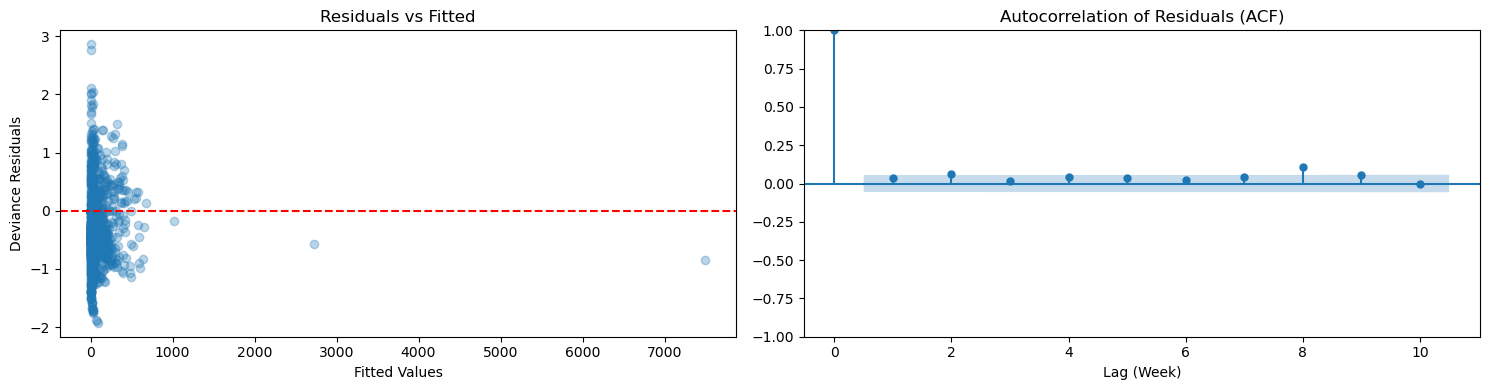

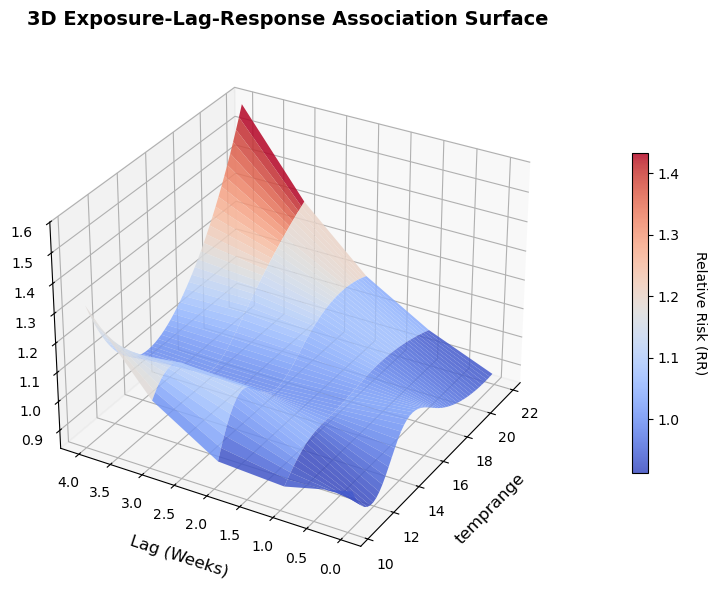

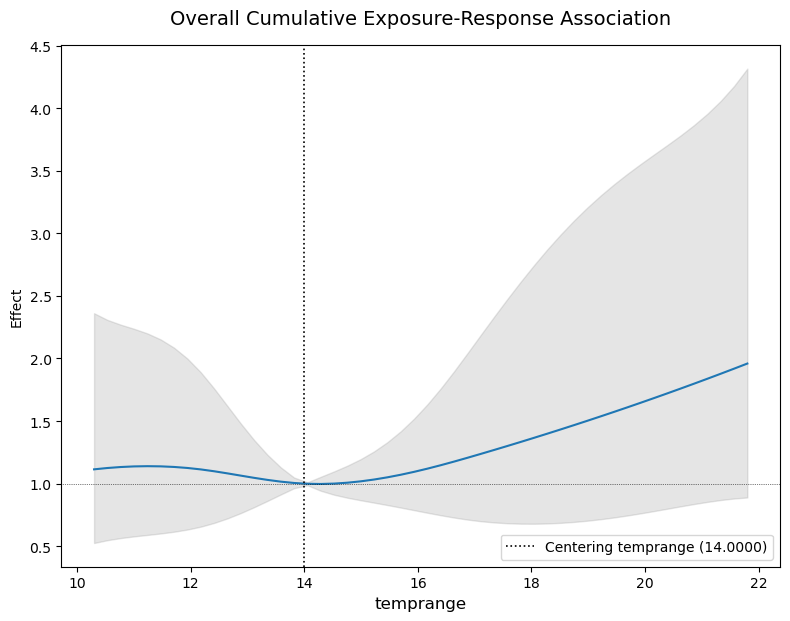

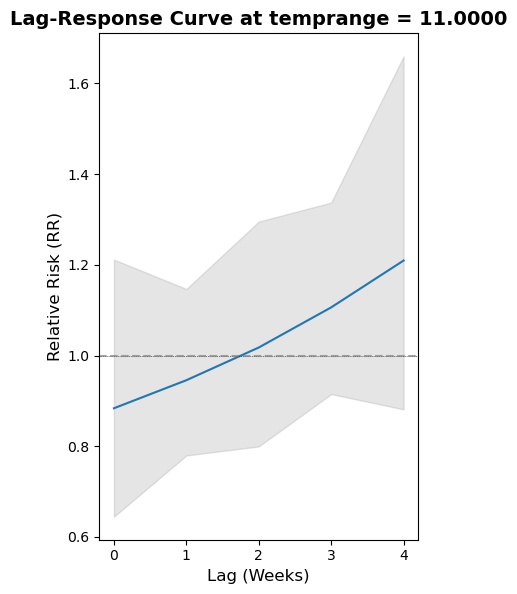

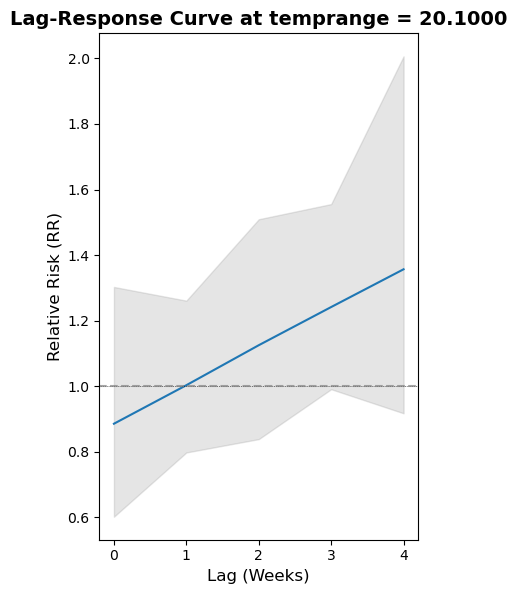

**====================================================================== temp ======================================================================**

================================================== Hyperparameter tuning ==================================================
============================== Tuning CrossBasis settings ==============================
BIC for (2, 3, 2, 3): 10313.06
BIC for (2, 3, 2, 4): 10326.85
BIC for (2, 3, 3, 3): 10313.06
BIC for (2, 3, 3, 4): 10326.85
BIC for (2, 4, 2, 3): 10316.25
BIC for (2, 4, 2, 4): 10339.10
BIC for (2, 4, 3, 3): 10316.25
BIC for (2, 4, 3, 4): 10339.10
BIC for (3, 3, 2, 3): 10313.06
BIC for (3, 3, 2, 4): 10326.85
BIC for (3, 3, 3, 3): 10313.06
BIC for (3, 3, 3, 4): 10326.85
BIC for (3, 4, 2, 3): 10316.25
BIC for (3, 4, 2, 4): 10339.10
BIC for (3, 4, 3, 3): 10316.25
BIC for (3, 4, 3, 4): 10339.10
Best CrossBasis setting: (2, 3, 2, 3) (BIC = 10313.06)

============================== Tuning smoother degrees of freedom ==============================
Degrees of freedom (10, 4, 5): BIC=9444.3019 | sum(EDF)=29.1258
Degrees of freedom (10, 4, 6): BIC=9461.3497 | sum(EDF)=30.1364
Degrees of

,alpha,AIC,BIC,GCV,EDF
gcv,"[490.35771466913565, 5.175245724283347, 216.45...",8033.435991,8351.230534,1.107205,61.956738
KFold,"(1.0, 5.011872336272722, 5.011872336272722)",7957.804668,8177.6919,1.072409,42.868878



============================== Tuning Negative Binomial dispersion parameter ==============================
Dispersion   1.0: Pearson ratio = 2.9428 | BIC = 8177.6919
Dispersion   1.5: Pearson ratio = 2.2410 | BIC = 8194.1139
Dispersion   2.0: Pearson ratio = 1.5322 | BIC = 8275.3687
Dispersion   3.0: Pearson ratio = 0.8964 | BIC = 8477.6507
Dispersion   4.0: Pearson ratio = 0.6472 | BIC = 8672.3542
Dispersion   5.0: Pearson ratio = 0.5157 | BIC = 8849.0060

Best dispersion parameter: 3.0 (Pearson ratio = 0.8964)

================================================== Negative Binomial GLMGam ==================================================
                 Generalized Linear Model Regression Results                  
Dep. Variable:                     H1   No. Observations:                 1248
Model:                         GLMGam   Df Residuals:                  1206.00
Model Family:        NegativeBinomial   Df Model:                        41.00
Link Function:                    Lo

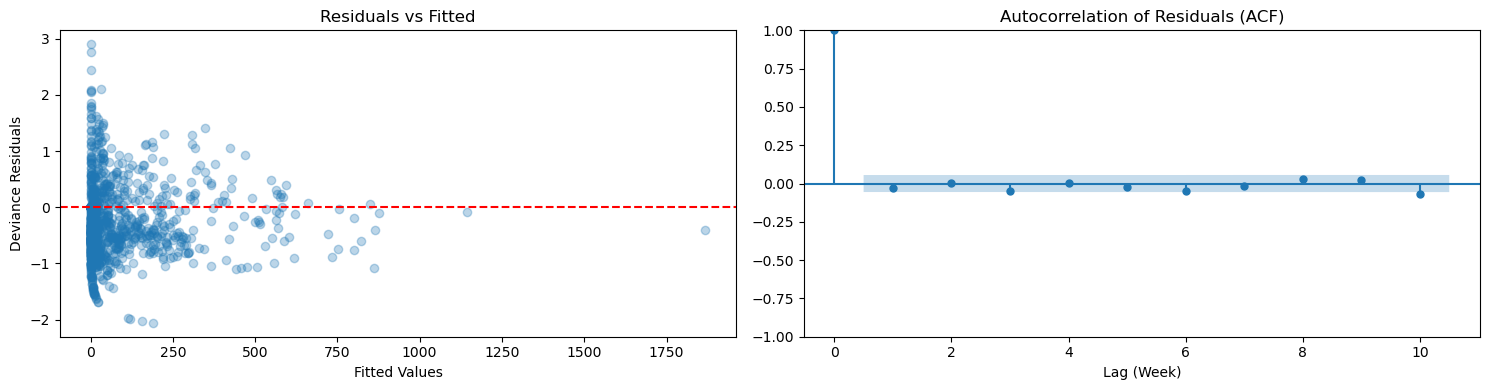

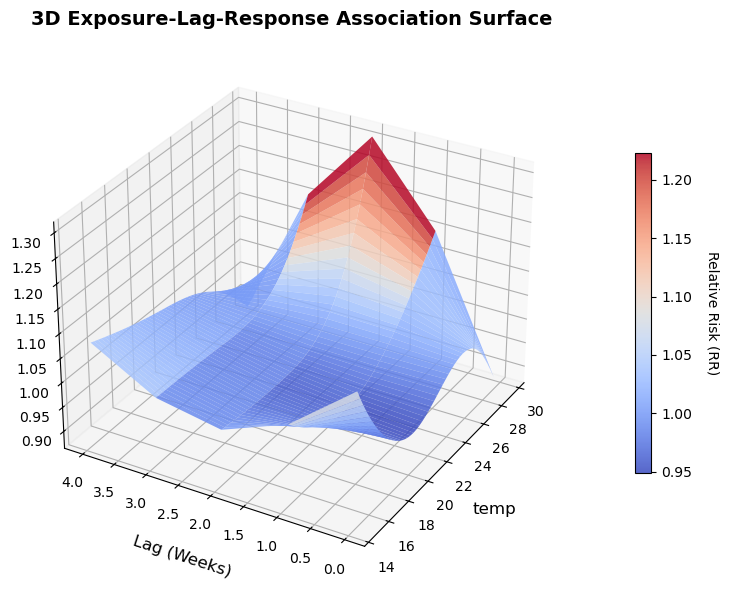

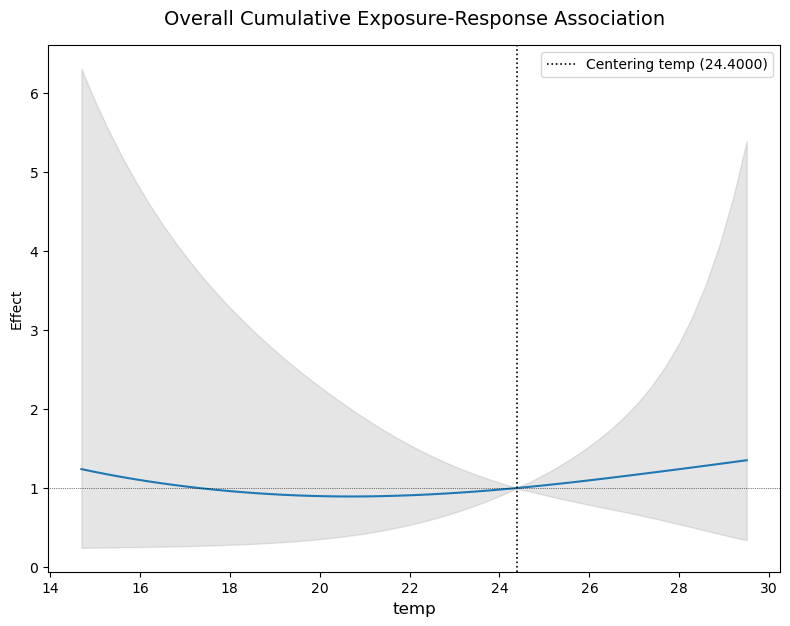

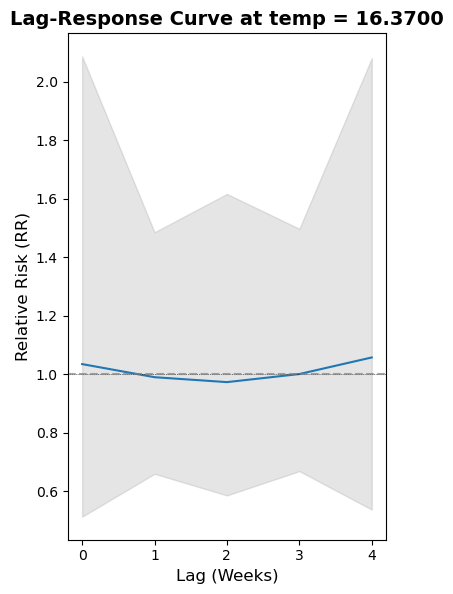

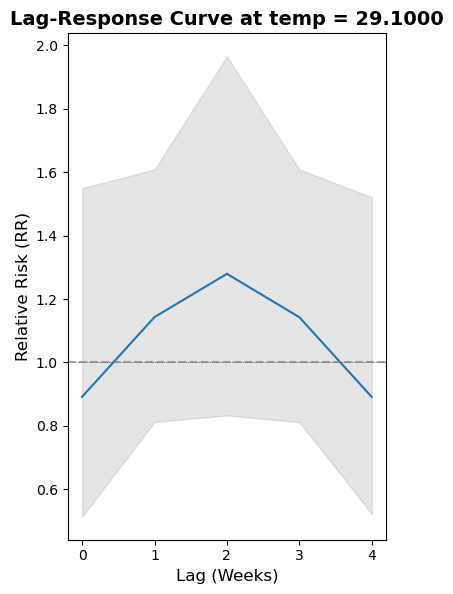

**====================================================================== RH ======================================================================**

================================================== Hyperparameter tuning ==================================================
============================== Tuning CrossBasis settings ==============================
BIC for (2, 3, 2, 3): 10395.59
BIC for (2, 3, 2, 4): 10403.25
BIC for (2, 3, 3, 3): 10395.59
BIC for (2, 3, 3, 4): 10403.25
BIC for (2, 4, 2, 3): 10405.35
BIC for (2, 4, 2, 4): 10412.03
BIC for (2, 4, 3, 3): 10405.35
BIC for (2, 4, 3, 4): 10412.03
BIC for (3, 3, 2, 3): 10395.59
BIC for (3, 3, 2, 4): 10403.25
BIC for (3, 3, 3, 3): 10395.59
BIC for (3, 3, 3, 4): 10403.25
BIC for (3, 4, 2, 3): 10405.35
BIC for (3, 4, 2, 4): 10412.03
BIC for (3, 4, 3, 3): 10405.35
BIC for (3, 4, 3, 4): 10412.03
Best CrossBasis setting: (2, 3, 2, 3) (BIC = 10395.59)

============================== Tuning smoother degrees of freedom ==============================
Degrees of freedom (10, 4, 5): BIC=9494.3773 | sum(EDF)=29.7011
Degrees of freedom (10, 4, 6): BIC=9445.7099 | sum(EDF)=30.8029
Degrees of

,alpha,AIC,BIC,GCV,EDF
gcv,"[578.2372036145539, 12.528388552489742, 107.31...",8101.310874,8640.347457,1.192353,105.089747
KFold,"(25.118864315095795, 25.118864315095795, 25.11...",7941.422192,8166.661796,1.074269,43.912368



============================== Tuning Negative Binomial dispersion parameter ==============================
Dispersion   1.0: Pearson ratio = 2.3743 | BIC = 8166.6618
Dispersion   1.5: Pearson ratio = 1.8291 | BIC = 8189.0401
Dispersion   2.0: Pearson ratio = 1.4320 | BIC = 8275.3179
Dispersion   3.0: Pearson ratio = 0.9648 | BIC = 8485.8154
Dispersion   4.0: Pearson ratio = 0.6973 | BIC = 8683.3726
Dispersion   5.0: Pearson ratio = 0.5392 | BIC = 8861.3875

Best dispersion parameter: 3.0 (Pearson ratio = 0.9648)

================================================== Negative Binomial GLMGam ==================================================
                 Generalized Linear Model Regression Results                  
Dep. Variable:                     H1   No. Observations:                 1248
Model:                         GLMGam   Df Residuals:                  1203.75
Model Family:        NegativeBinomial   Df Model:                        43.25
Link Function:                    Lo

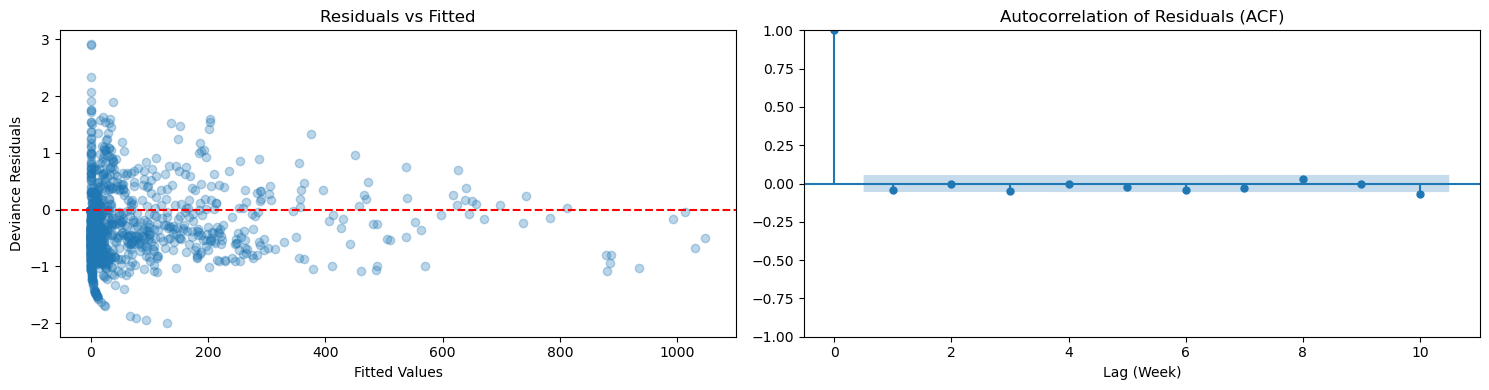

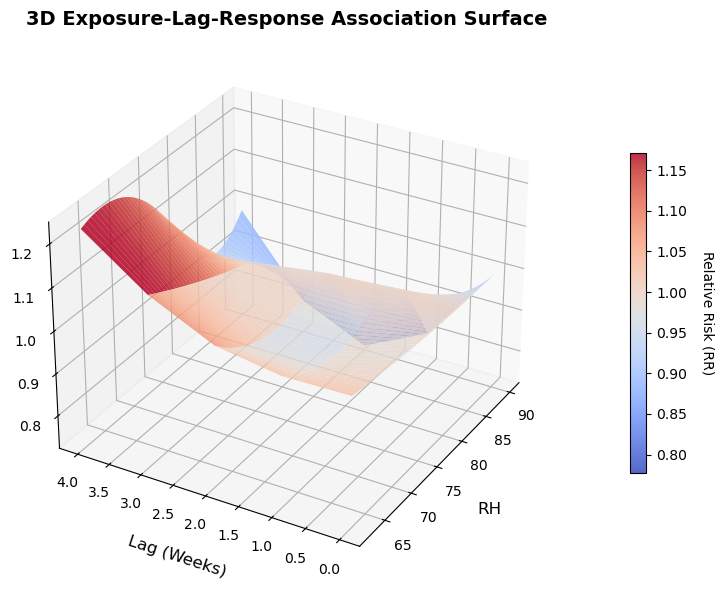

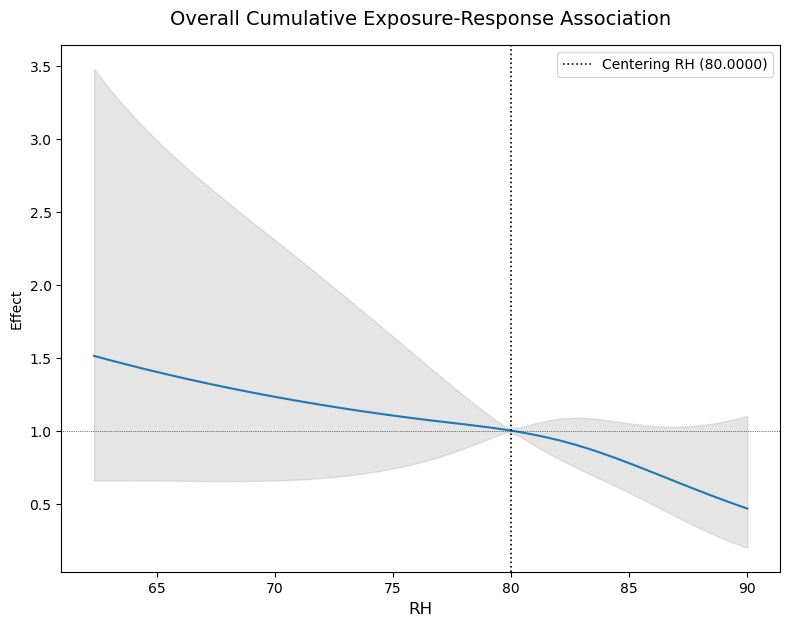

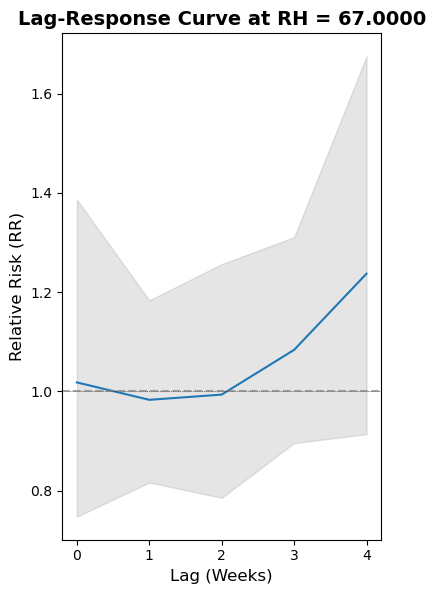

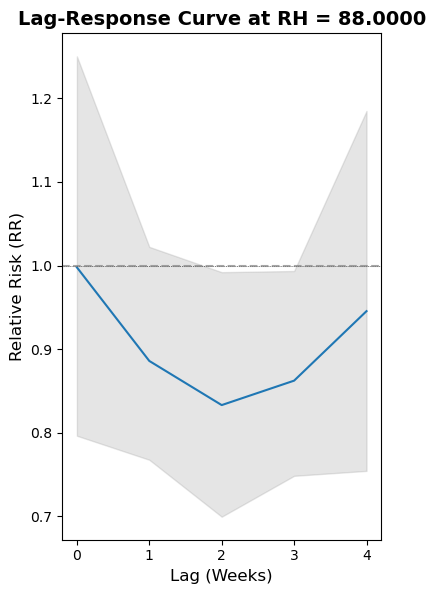

**====================================================================== SR ======================================================================**

================================================== Hyperparameter tuning ==================================================
============================== Tuning CrossBasis settings ==============================
BIC for (2, 3, 2, 3): 10392.35
BIC for (2, 3, 2, 4): 10400.31
BIC for (2, 3, 3, 3): 10392.35
BIC for (2, 3, 3, 4): 10400.31
BIC for (2, 4, 2, 3): 10400.90
BIC for (2, 4, 2, 4): 10411.69
BIC for (2, 4, 3, 3): 10400.90
BIC for (2, 4, 3, 4): 10411.69
BIC for (3, 3, 2, 3): 10392.35
BIC for (3, 3, 2, 4): 10400.31
BIC for (3, 3, 3, 3): 10392.35
BIC for (3, 3, 3, 4): 10400.31
BIC for (3, 4, 2, 3): 10400.90
BIC for (3, 4, 2, 4): 10411.69
BIC for (3, 4, 3, 3): 10400.90
BIC for (3, 4, 3, 4): 10411.69
Best CrossBasis setting: (2, 3, 2, 3) (BIC = 10392.35)

============================== Tuning smoother degrees of freedom ==============================
Degrees of freedom (10, 4, 5): BIC=9465.0838 | sum(EDF)=29.4308
Degrees of freedom (10, 4, 6): BIC=9408.6388 | sum(EDF)=30.7182
Degrees of

,alpha,AIC,BIC,GCV,EDF
gcv,"[4.3786536116859654e+35, 4747.8970354937455, 4...",22193.596213,22193.596213,1.0,0.0
KFold,"(125.89254117941663, 25.118864315095795, 5.011...",7942.879894,8166.91931,1.073851,43.678382



============================== Tuning Negative Binomial dispersion parameter ==============================
Dispersion   1.0: Pearson ratio = 1.8940 | BIC = 8166.9193
Dispersion   1.5: Pearson ratio = 1.3900 | BIC = 8190.9423
Dispersion   2.0: Pearson ratio = 1.0838 | BIC = 8277.8522
Dispersion   3.0: Pearson ratio = 0.7512 | BIC = 8481.1867
Dispersion   4.0: Pearson ratio = 0.5859 | BIC = 8678.5450
Dispersion   5.0: Pearson ratio = 0.4869 | BIC = 8857.0778

Best dispersion parameter: 2.0 (Pearson ratio = 1.0838)

================================================== Negative Binomial GLMGam ==================================================
                 Generalized Linear Model Regression Results                  
Dep. Variable:                     H1   No. Observations:                 1248
Model:                         GLMGam   Df Residuals:                  1204.57
Model Family:        NegativeBinomial   Df Model:                        42.43
Link Function:                    Lo

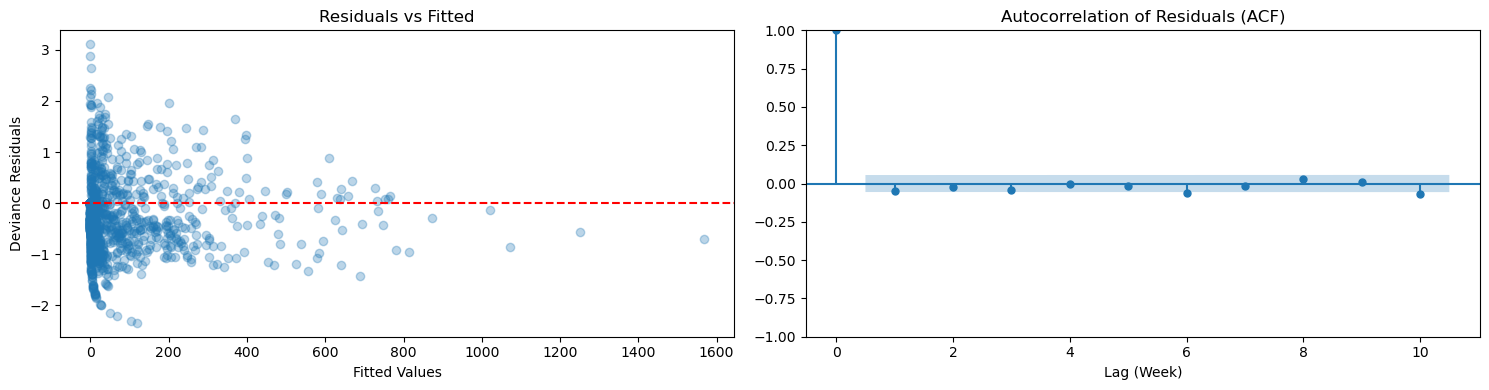

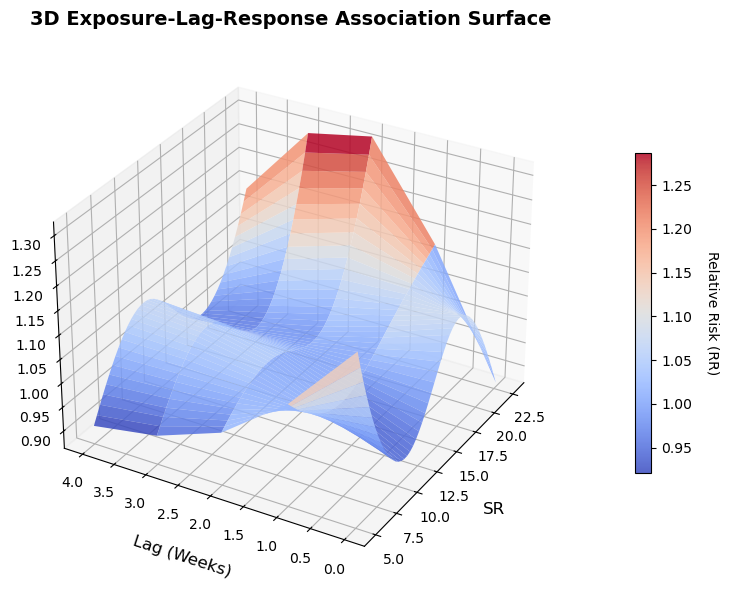

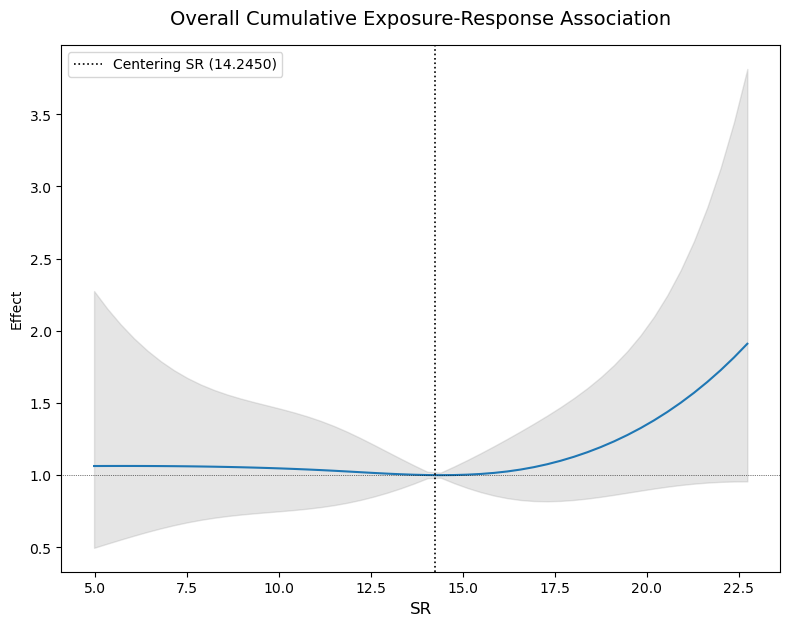

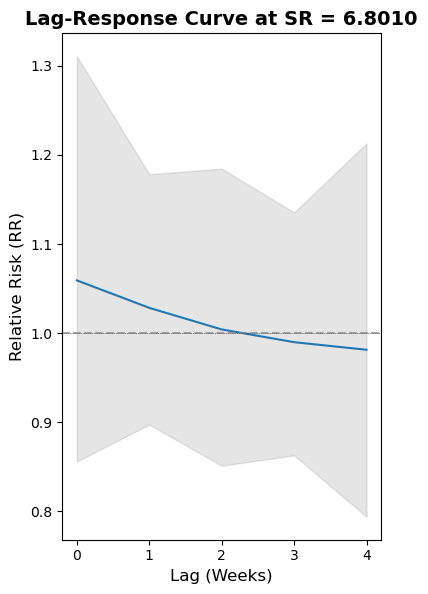

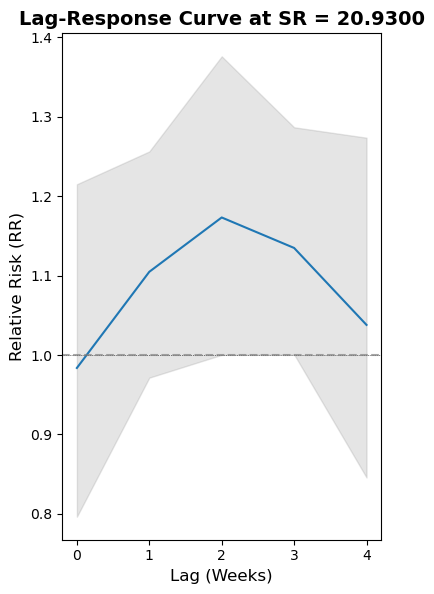

**====================================================================== AP ======================================================================**

================================================== Hyperparameter tuning ==================================================
============================== Tuning CrossBasis settings ==============================
BIC for (2, 3, 2, 3): 10422.18
BIC for (2, 3, 2, 4): 10441.07
BIC for (2, 3, 3, 3): 10422.18
BIC for (2, 3, 3, 4): 10441.07
BIC for (2, 4, 2, 3): 10436.31
BIC for (2, 4, 2, 4): 10462.98
BIC for (2, 4, 3, 3): 10436.31
BIC for (2, 4, 3, 4): 10462.98
BIC for (3, 3, 2, 3): 10422.18
BIC for (3, 3, 2, 4): 10441.07
BIC for (3, 3, 3, 3): 10422.18
BIC for (3, 3, 3, 4): 10441.07
BIC for (3, 4, 2, 3): 10436.31
BIC for (3, 4, 2, 4): 10462.98
BIC for (3, 4, 3, 3): 10436.31
BIC for (3, 4, 3, 4): 10462.98
Best CrossBasis setting: (2, 3, 2, 3) (BIC = 10422.18)

============================== Tuning smoother degrees of freedom ==============================
Degrees of freedom (10, 4, 5): BIC=9445.9865 | sum(EDF)=29.3205
Degrees of freedom (10, 4, 6): BIC=9458.6371 | sum(EDF)=30.6616
Degrees of

,alpha,AIC,BIC,GCV,EDF
gcv,"[1.295829501187849e+41, 1.716500848916235e-07,...",22193.596213,22193.596213,1.0,0.0
KFold,"(3162.2776601683795, 5.011872336272722, 3162.2...",8139.959376,8335.685741,1.064075,38.158513



============================== Tuning Negative Binomial dispersion parameter ==============================
Dispersion   1.0: Pearson ratio = 1.5954 | BIC = 8335.6857
Dispersion   1.5: Pearson ratio = 1.2195 | BIC = 8324.2497
Dispersion   2.0: Pearson ratio = 0.9596 | BIC = 8376.5257
Dispersion   3.0: Pearson ratio = 0.7204 | BIC = 8549.6175
Dispersion   4.0: Pearson ratio = 0.5884 | BIC = 8726.0134
Dispersion   5.0: Pearson ratio = 0.5012 | BIC = 8889.3989

Best dispersion parameter: 2.0 (Pearson ratio = 0.9596)

================================================== Negative Binomial GLMGam ==================================================
                 Generalized Linear Model Regression Results                  
Dep. Variable:                     H1   No. Observations:                 1248
Model:                         GLMGam   Df Residuals:                  1211.56
Model Family:        NegativeBinomial   Df Model:                        35.44
Link Function:                    Lo

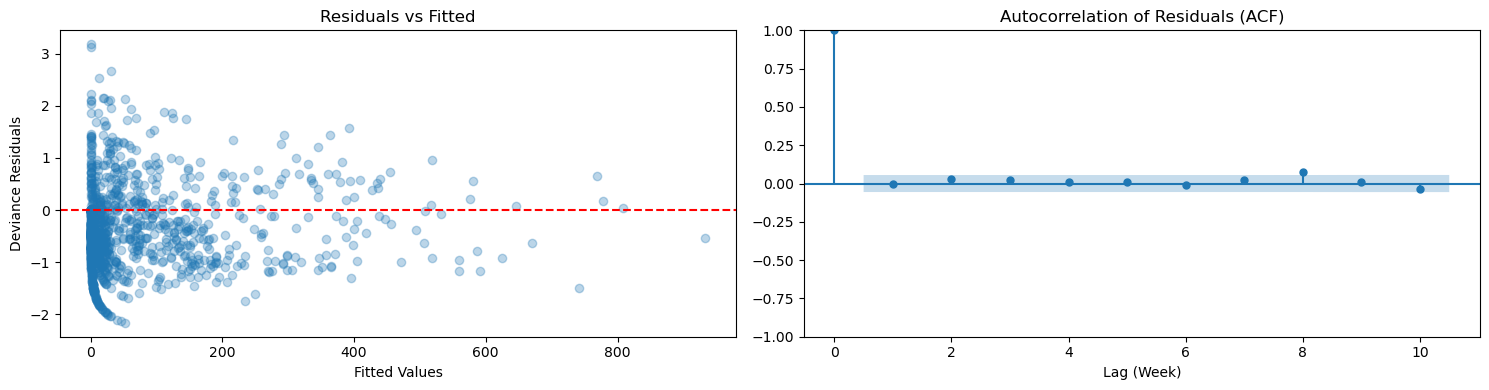

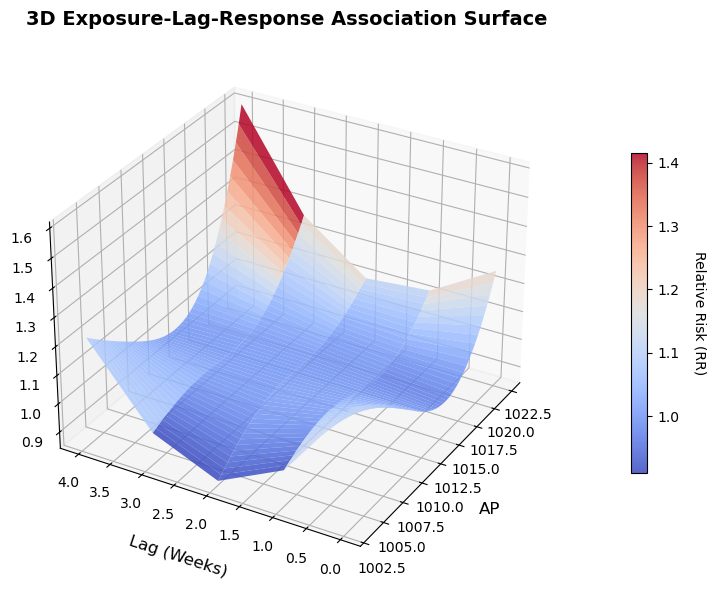

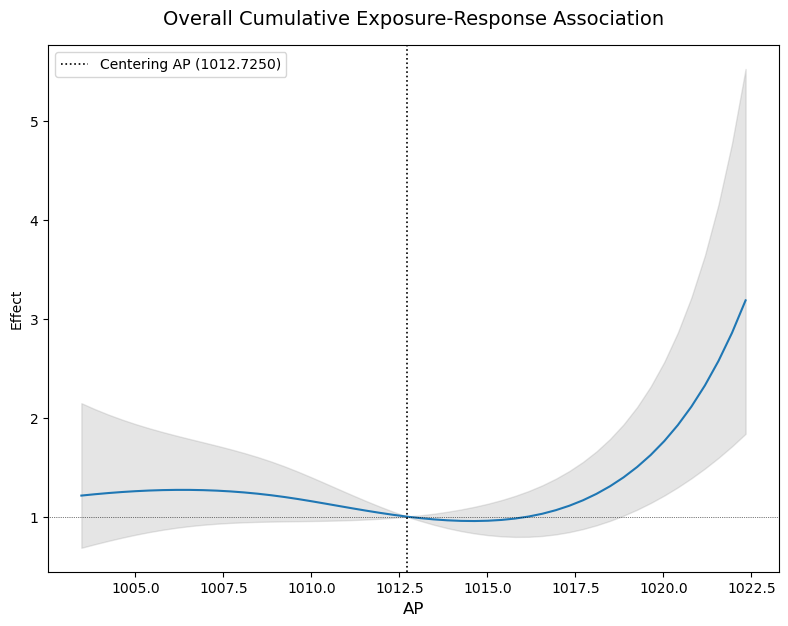

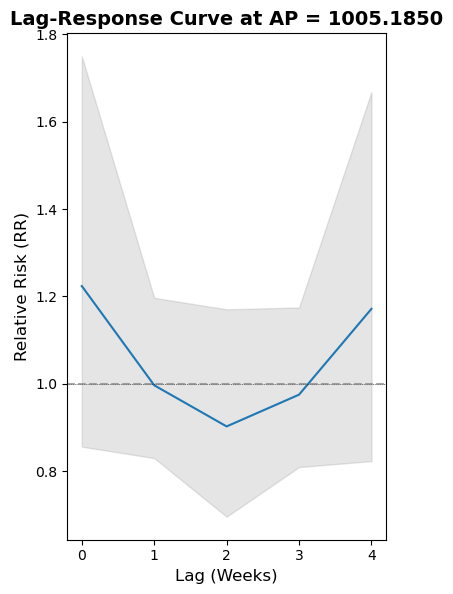

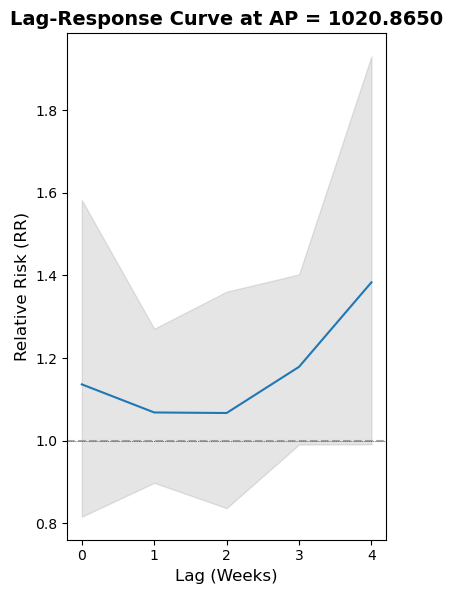

**====================================================================== DPT ======================================================================**

================================================== Hyperparameter tuning ==================================================
============================== Tuning CrossBasis settings ==============================
BIC for (2, 3, 2, 3): 10349.55
BIC for (2, 3, 2, 4): 10353.68
BIC for (2, 3, 3, 3): 10349.55
BIC for (2, 3, 3, 4): 10353.68
BIC for (2, 4, 2, 3): 10358.32
BIC for (2, 4, 2, 4): 10367.66
BIC for (2, 4, 3, 3): 10358.32
BIC for (2, 4, 3, 4): 10367.66
BIC for (3, 3, 2, 3): 10349.55
BIC for (3, 3, 2, 4): 10353.68
BIC for (3, 3, 3, 3): 10349.55
BIC for (3, 3, 3, 4): 10353.68
BIC for (3, 4, 2, 3): 10358.32
BIC for (3, 4, 2, 4): 10367.66
BIC for (3, 4, 3, 3): 10358.32
BIC for (3, 4, 3, 4): 10367.66
Best CrossBasis setting: (2, 3, 2, 3) (BIC = 10349.55)

============================== Tuning smoother degrees of freedom ==============================
Degrees of freedom (10, 4, 5): BIC=9477.2604 | sum(EDF)=29.4103
Degrees of freedom (10, 4, 6): BIC=9455.3708 | sum(EDF)=30.4564
Degrees of

,alpha,AIC,BIC,GCV,EDF
gcv,"[7.795274036234108e+33, 1.676270360269824e-20,...",22193.596213,22193.596213,1.0,0.0
KFold,"(125.89254117941663, 5.011872336272722, 5.0118...",7968.368871,8187.240307,1.072057,42.67084



============================== Tuning Negative Binomial dispersion parameter ==============================
Dispersion   1.0: Pearson ratio = 1.8241 | BIC = 8187.2403
Dispersion   1.5: Pearson ratio = 1.3416 | BIC = 8202.6596
Dispersion   2.0: Pearson ratio = 1.0569 | BIC = 8285.0229
Dispersion   3.0: Pearson ratio = 0.7483 | BIC = 8483.5906
Dispersion   4.0: Pearson ratio = 0.5918 | BIC = 8678.1977
Dispersion   5.0: Pearson ratio = 0.4947 | BIC = 8855.0304

Best dispersion parameter: 2.0 (Pearson ratio = 1.0569)

================================================== Negative Binomial GLMGam ==================================================
                 Generalized Linear Model Regression Results                  
Dep. Variable:                     H1   No. Observations:                 1248
Model:                         GLMGam   Df Residuals:                  1205.54
Model Family:        NegativeBinomial   Df Model:                        41.46
Link Function:                    Lo

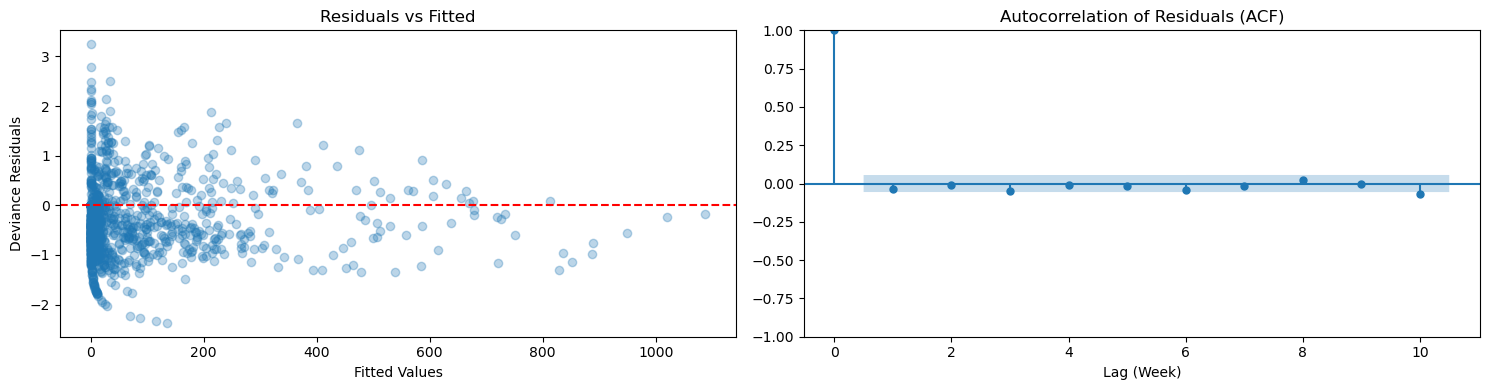

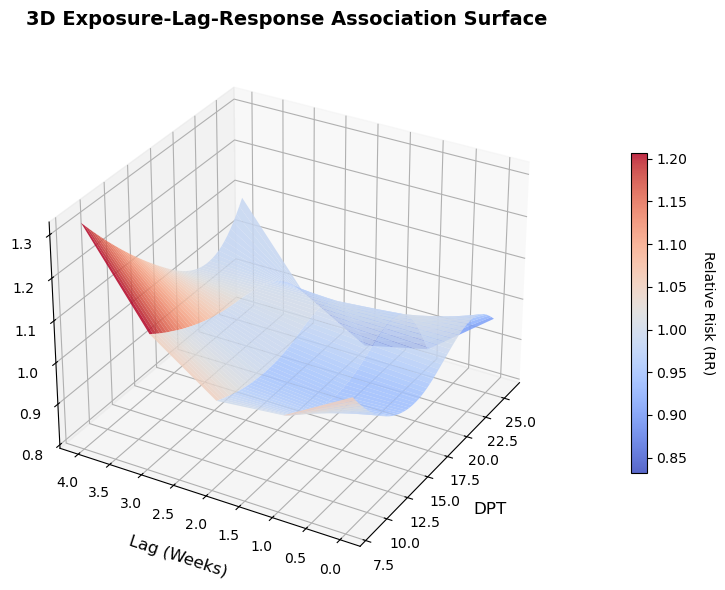

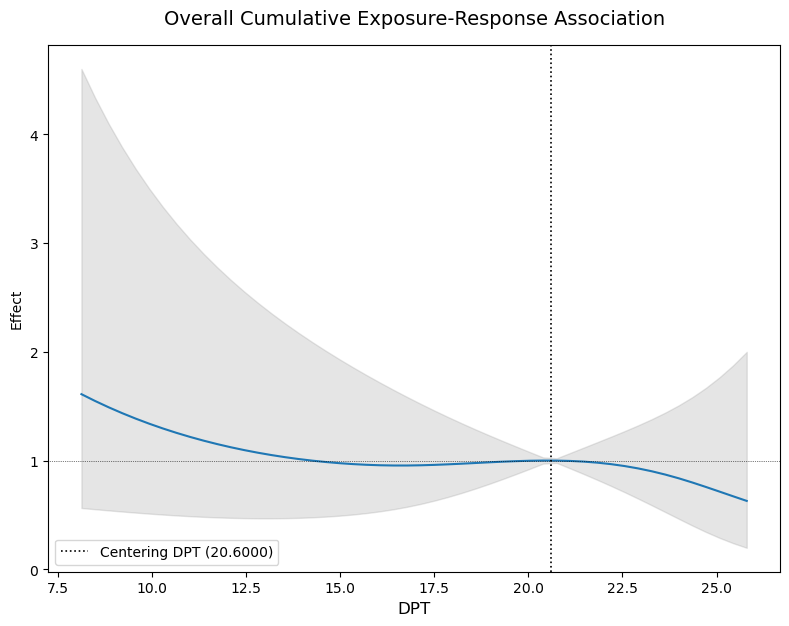

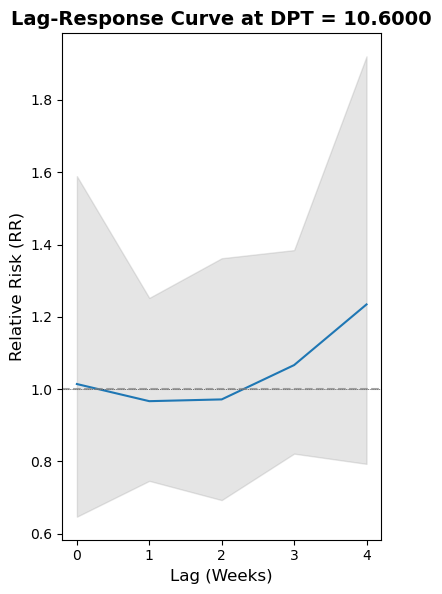

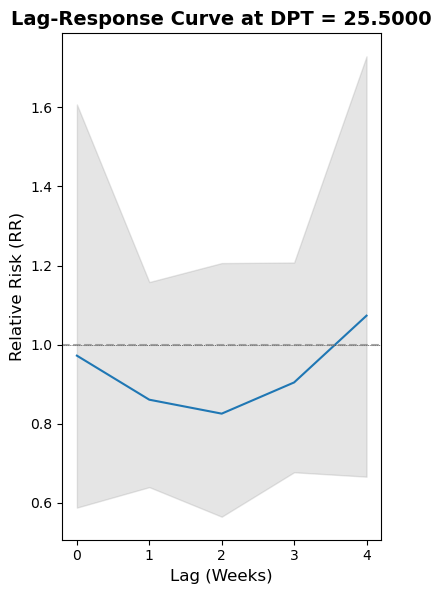

**====================================================================== WS ======================================================================**

================================================== Hyperparameter tuning ==================================================
============================== Tuning CrossBasis settings ==============================
BIC for (2, 3, 2, 3): 10450.81
BIC for (2, 3, 2, 4): 10467.91
BIC for (2, 3, 3, 3): 10450.81
BIC for (2, 3, 3, 4): 10467.91
BIC for (2, 4, 2, 3): 10467.15
BIC for (2, 4, 2, 4): 10490.19
BIC for (2, 4, 3, 3): 10467.15
BIC for (2, 4, 3, 4): 10490.19
BIC for (3, 3, 2, 3): 10450.81
BIC for (3, 3, 2, 4): 10467.91
BIC for (3, 3, 3, 3): 10450.81
BIC for (3, 3, 3, 4): 10467.91
BIC for (3, 4, 2, 3): 10467.15
BIC for (3, 4, 2, 4): 10490.19
BIC for (3, 4, 3, 3): 10467.15
BIC for (3, 4, 3, 4): 10490.19
Best CrossBasis setting: (2, 3, 2, 3) (BIC = 10450.81)

============================== Tuning smoother degrees of freedom ==============================
Degrees of freedom (10, 4, 5): BIC=9485.7265 | sum(EDF)=30.9701
Degrees of freedom (10, 4, 6): BIC=9424.8883 | sum(EDF)=32.0597
Degrees of

,alpha,AIC,BIC,GCV,EDF
gcv,"[55.195256186143375, 13.414964201222663, 66.28...",7974.462942,8280.624728,1.102983,59.688833
KFold,"(5.011872336272722, 125.89254117941663, 630.95...",7947.409788,8144.957088,1.0647,38.513519



============================== Tuning Negative Binomial dispersion parameter ==============================
Dispersion   1.0: Pearson ratio = 2.8534 | BIC = 8144.9571
Dispersion   1.5: Pearson ratio = 2.1088 | BIC = 8170.6383
Dispersion   2.0: Pearson ratio = 1.5628 | BIC = 8276.0041
Dispersion   3.0: Pearson ratio = 0.9368 | BIC = 8505.3916
Dispersion   4.0: Pearson ratio = 0.6454 | BIC = 8693.3092
Dispersion   5.0: Pearson ratio = 0.4943 | BIC = 8862.3296

Best dispersion parameter: 3.0 (Pearson ratio = 0.9368)

================================================== Negative Binomial GLMGam ==================================================
                 Generalized Linear Model Regression Results                  
Dep. Variable:                     H1   No. Observations:                 1248
Model:                         GLMGam   Df Residuals:                  1203.13
Model Family:        NegativeBinomial   Df Model:                        43.87
Link Function:                    Lo

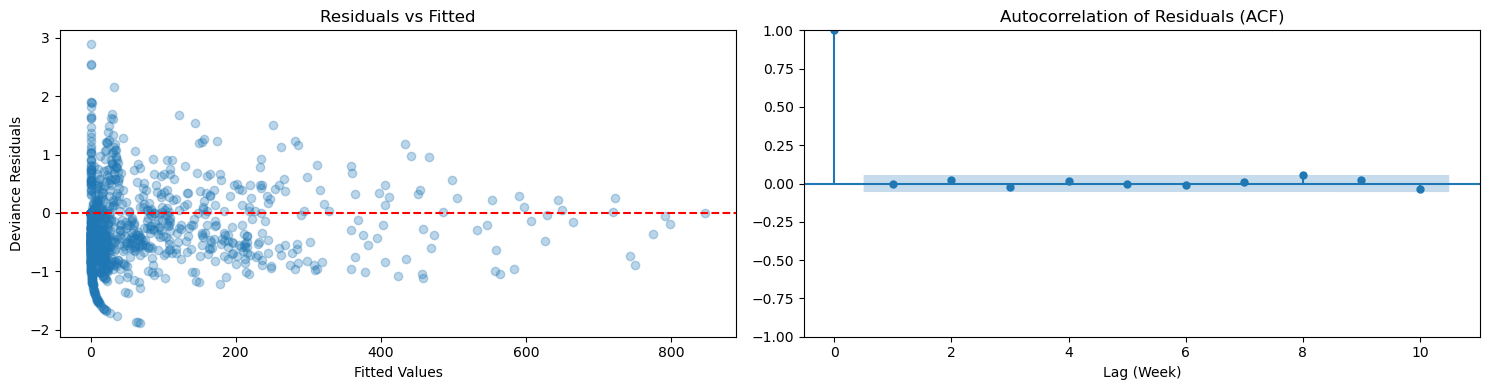

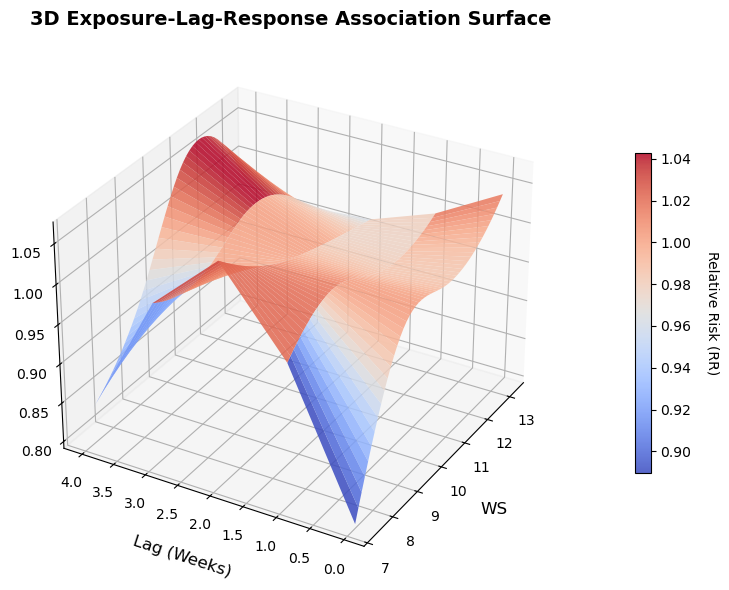

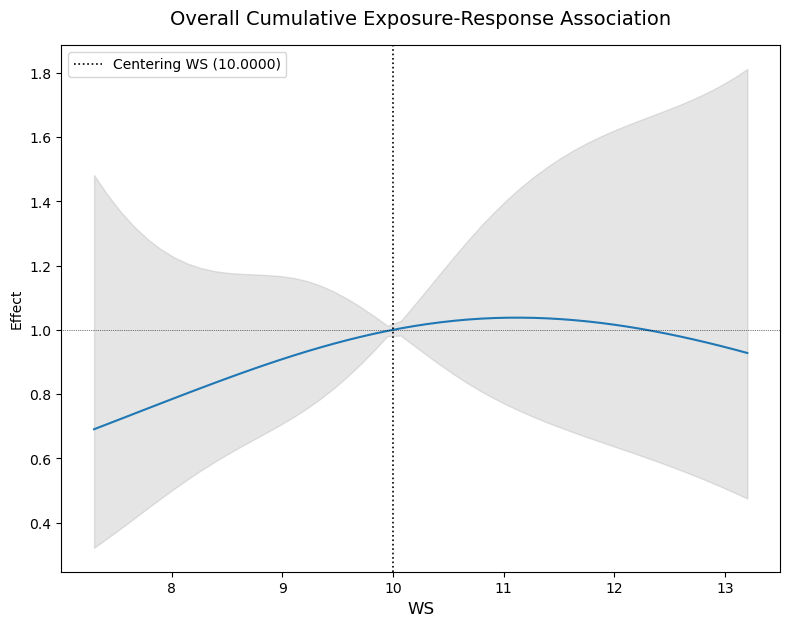

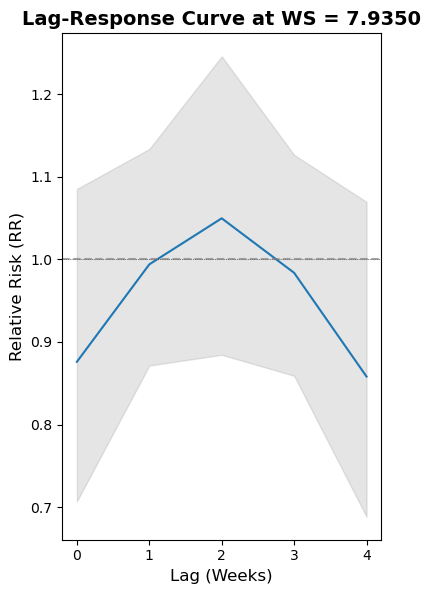

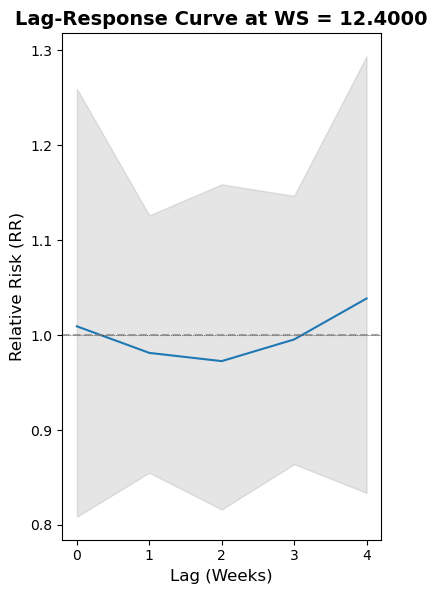

**====================================================================== UV ======================================================================**

================================================== Hyperparameter tuning ==================================================
============================== Tuning CrossBasis settings ==============================
BIC for (2, 3, 2, 3): 10390.31
BIC for (2, 3, 2, 4): 10407.32
BIC for (2, 3, 3, 3): 10390.31
BIC for (2, 3, 3, 4): 10407.32
BIC for (2, 4, 2, 3): 10401.67
BIC for (2, 4, 2, 4): 10425.26
BIC for (2, 4, 3, 3): 10401.67
BIC for (2, 4, 3, 4): 10425.26
BIC for (3, 3, 2, 3): 10390.31
BIC for (3, 3, 2, 4): 10407.32
BIC for (3, 3, 3, 3): 10390.31
BIC for (3, 3, 3, 4): 10407.32
BIC for (3, 4, 2, 3): 10401.67
BIC for (3, 4, 2, 4): 10425.26
BIC for (3, 4, 3, 3): 10401.67
BIC for (3, 4, 3, 4): 10425.26
Best CrossBasis setting: (2, 3, 2, 3) (BIC = 10390.31)

============================== Tuning smoother degrees of freedom ==============================
Degrees of freedom (10, 4, 5): BIC=9446.2472 | sum(EDF)=29.7526
Degrees of freedom (10, 4, 6): BIC=9414.6393 | sum(EDF)=30.8813
Degrees of

,alpha,AIC,BIC,GCV,EDF
gcv,"[42.09956323152623, 12.779890618417861, 75.781...",7945.457642,8178.891393,1.077125,45.509887
KFold,"(125.89254117941663, 25.118864315095795, 3162....",7994.004464,8199.382834,1.067393,40.040253



============================== Tuning Negative Binomial dispersion parameter ==============================
Dispersion   1.0: Pearson ratio = 1.9834 | BIC = 8199.3828
Dispersion   1.5: Pearson ratio = 1.4079 | BIC = 8218.1532
Dispersion   2.0: Pearson ratio = 1.0715 | BIC = 8296.6474
Dispersion   3.0: Pearson ratio = 0.7187 | BIC = 8491.9815
Dispersion   4.0: Pearson ratio = 0.5435 | BIC = 8680.2059
Dispersion   5.0: Pearson ratio = 0.4407 | BIC = 8852.3492

Best dispersion parameter: 2.0 (Pearson ratio = 1.0715)

================================================== Negative Binomial GLMGam ==================================================
                 Generalized Linear Model Regression Results                  
Dep. Variable:                     H1   No. Observations:                 1248
Model:                         GLMGam   Df Residuals:                  1207.86
Model Family:        NegativeBinomial   Df Model:                        39.14
Link Function:                    Lo

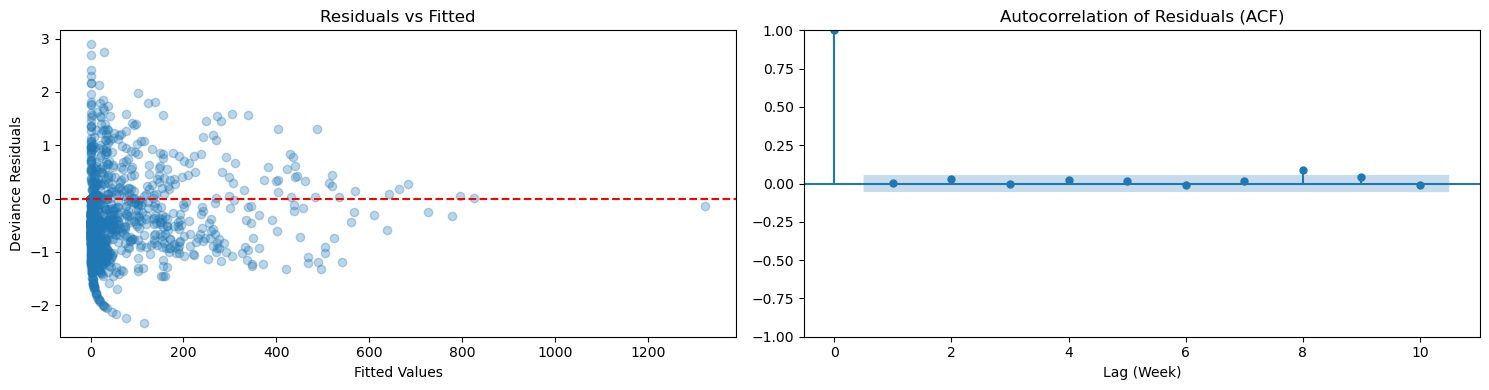

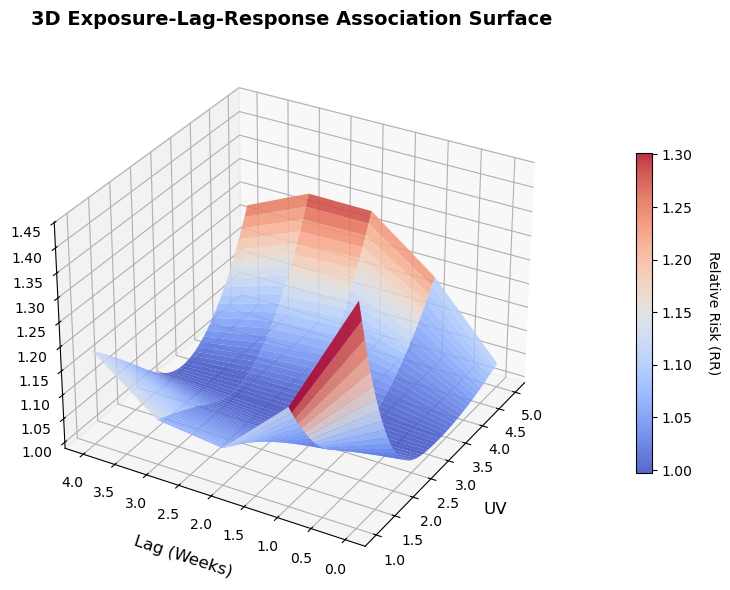

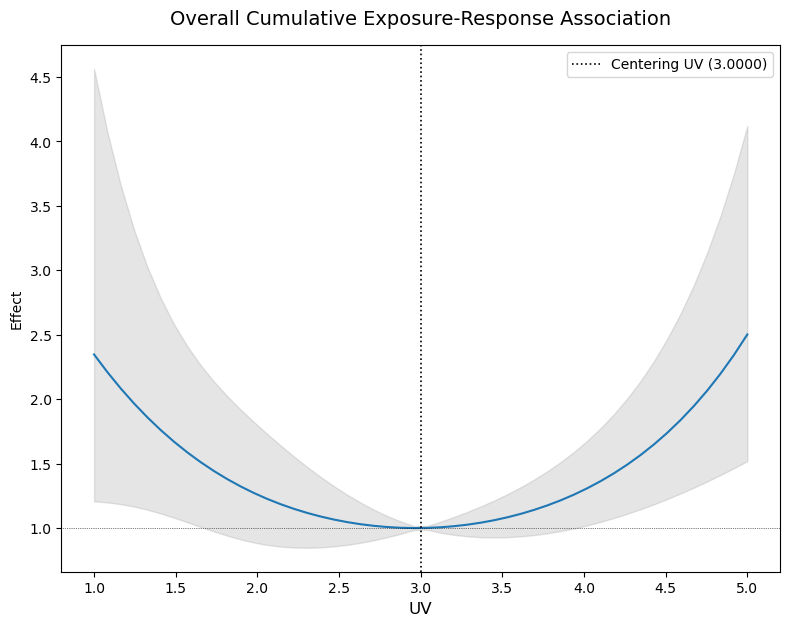

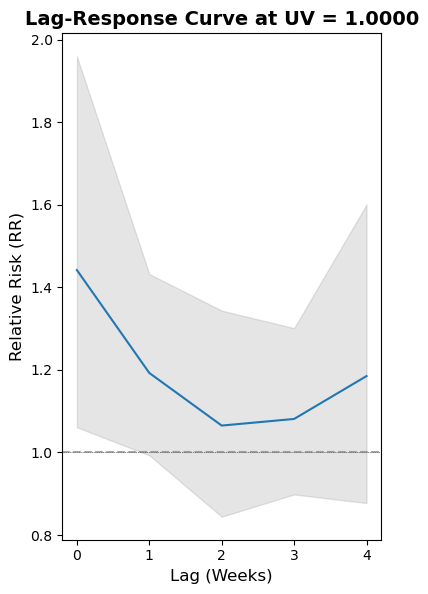

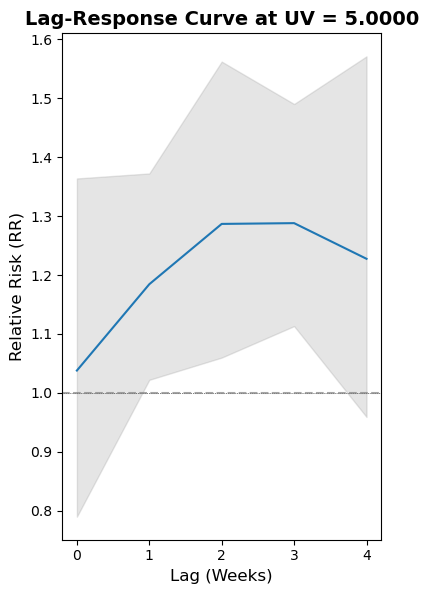

In [22]:
# All meteorological variables for H1
tar_var = "H1"
for exp in mete_col:
    exp_col_list = [exp]

    display(Markdown(f"**{'='*70} {exp} {'='*70}**"))

    pred, model_data, cb_list, nb_result = DLNM_NB(
        df, max_lag=4, tar_var=tar_var, exp_col_list=exp_col_list, linear_predictors_list=linear_predictors_list, bs_name_lst=bs_name_lst, ccs_name_lst=ccs_name_lst,
        cb_grid=cb_grid, smoother_grid=smoother_grid, disp_grid=disp_grid, criterion_lst=["gcv"]
    )


**============================== temprange ==============================**

================================================== Hyperparameter tuning ==================================================
============================== Tuning CrossBasis settings ==============================
BIC for (2, 3, 2, 3): 15008.52
BIC for (2, 3, 2, 4): 15024.21
BIC for (2, 3, 3, 3): 15008.52
BIC for (2, 3, 3, 4): 15024.21
BIC for (2, 4, 2, 3): 15028.56
BIC for (2, 4, 2, 4): 15043.92
BIC for (2, 4, 3, 3): 15028.56
BIC for (2, 4, 3, 4): 15043.92
BIC for (3, 3, 2, 3): 15008.52
BIC for (3, 3, 2, 4): 15024.21
BIC for (3, 3, 3, 3): 15008.52
BIC for (3, 3, 3, 4): 15024.21
BIC for (3, 4, 2, 3): 15028.56
BIC for (3, 4, 2, 4): 15043.92
BIC for (3, 4, 3, 3): 15028.56
BIC for (3, 4, 3, 4): 15043.92
Best CrossBasis setting: (2, 3, 2, 3) (BIC = 15008.52)

============================== Tuning smoother degrees of freedom ==============================
Degrees of freedom (10, 4, 5): BIC=14750.6451 | sum(EDF)=27.6968
Degrees of freedom (10, 4, 6): BIC=14740.9547 | sum(EDF)=28.5925
Degrees 

,alpha,AIC,BIC,GCV,EDF
gcv,"[1.307682759477385e-15, 1217.9189740715888, 5....",22259.656503,22259.656503,1.0,0.0
KFold,"(125.89254117941663, 15848.931924611108, 1.0)",14513.031321,14728.23375,1.070786,41.955536



============================== Tuning Negative Binomial dispersion parameter ==============================
Dispersion   1.0: Pearson ratio = 1.1670 | BIC = 14728.2337
Dispersion   1.5: Pearson ratio = 0.8053 | BIC = 14897.5025
Dispersion   2.0: Pearson ratio = 0.6184 | BIC = 15111.4797
Dispersion   3.0: Pearson ratio = 0.4249 | BIC = 15521.2336
Dispersion   4.0: Pearson ratio = 0.3247 | BIC = 15877.4035
Dispersion   5.0: Pearson ratio = 0.2631 | BIC = 16186.2205

Best dispersion parameter: 1.0 (Pearson ratio = 1.1670)

================================================== Negative Binomial GLMGam ==================================================
                 Generalized Linear Model Regression Results                  
Dep. Variable:                  AandB   No. Observations:                 1248
Model:                         GLMGam   Df Residuals:                  1206.04
Model Family:        NegativeBinomial   Df Model:                        40.96
Link Function:                

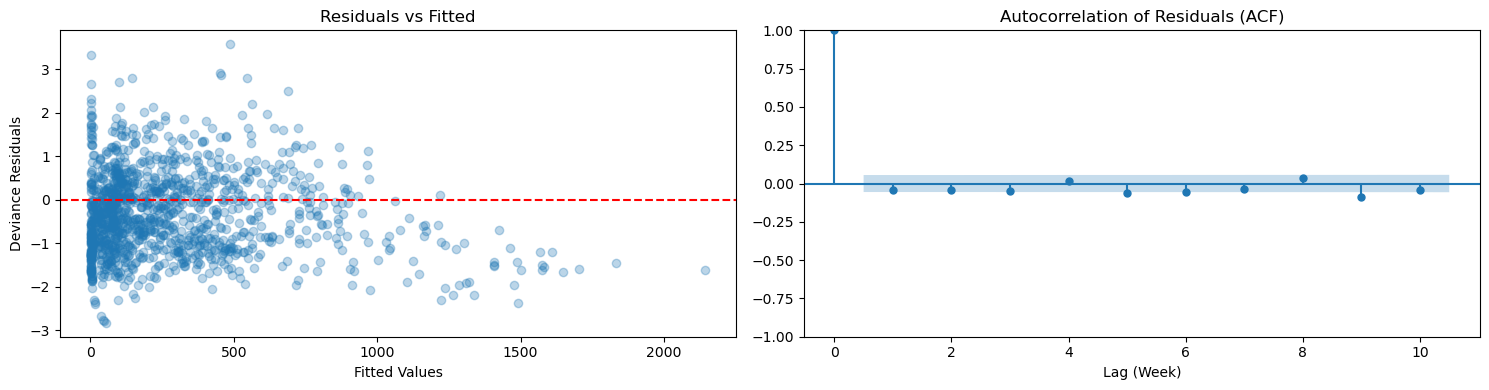

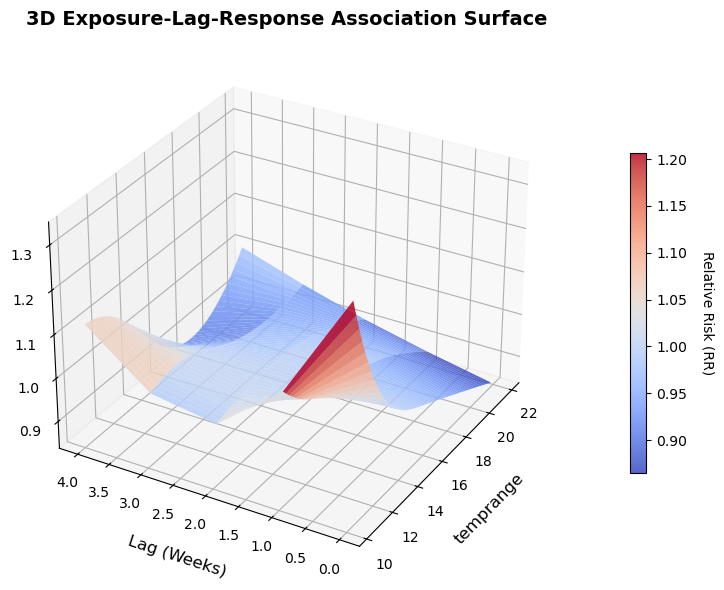

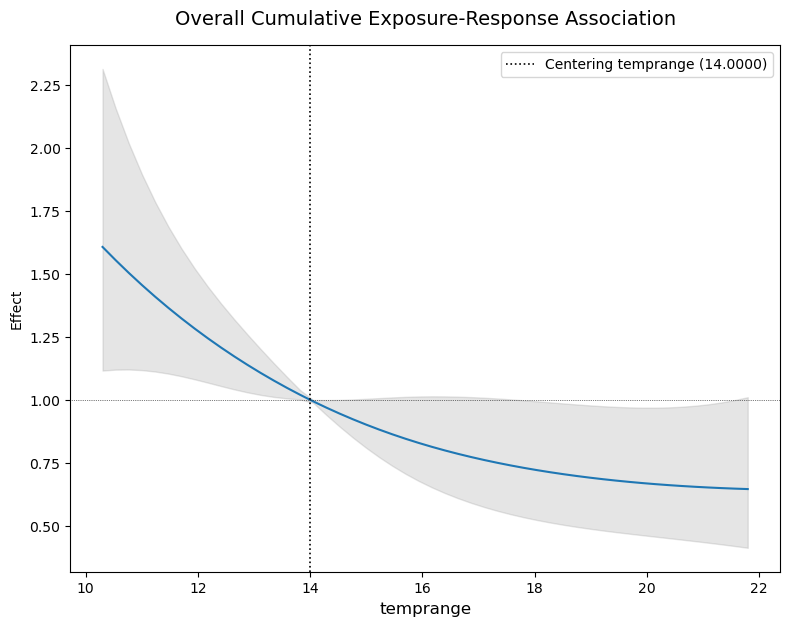

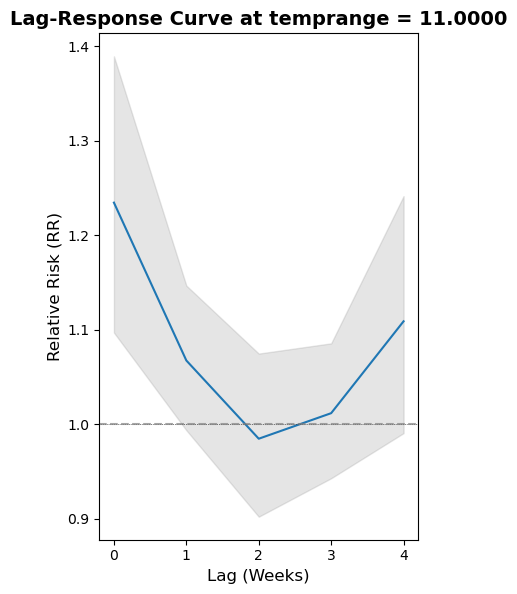

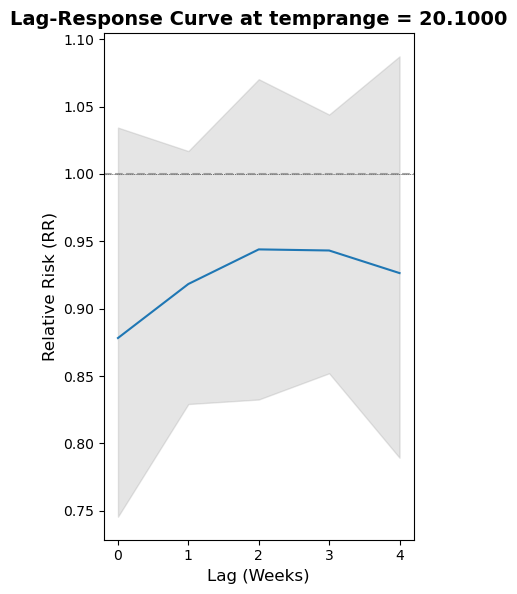

**============================== temp ==============================**

================================================== Hyperparameter tuning ==================================================
============================== Tuning CrossBasis settings ==============================
BIC for (2, 3, 2, 3): 14897.69
BIC for (2, 3, 2, 4): 14912.96
BIC for (2, 3, 3, 3): 14897.69
BIC for (2, 3, 3, 4): 14912.96
BIC for (2, 4, 2, 3): 14911.16
BIC for (2, 4, 2, 4): 14933.68
BIC for (2, 4, 3, 3): 14911.16
BIC for (2, 4, 3, 4): 14933.68
BIC for (3, 3, 2, 3): 14897.69
BIC for (3, 3, 2, 4): 14912.96
BIC for (3, 3, 3, 3): 14897.69
BIC for (3, 3, 3, 4): 14912.96
BIC for (3, 4, 2, 3): 14911.16
BIC for (3, 4, 2, 4): 14933.68
BIC for (3, 4, 3, 3): 14911.16
BIC for (3, 4, 3, 4): 14933.68
Best CrossBasis setting: (2, 3, 2, 3) (BIC = 14897.69)

============================== Tuning smoother degrees of freedom ==============================
Degrees of freedom (10, 4, 5): BIC=14763.1581 | sum(EDF)=27.5620
Degrees of freedom (10, 4, 6): BIC=14759.8104 | sum(EDF)=28.5697
Degrees 

,alpha,AIC,BIC,GCV,EDF
gcv,"[8.769585067131935, 24.278517435602566, 120.07...",14560.020186,14956.292381,1.136333,77.256621
KFold,"(15848.931924611108, 25.118864315095795, 630.9...",14519.493968,14756.952049,1.078532,46.294464



============================== Tuning Negative Binomial dispersion parameter ==============================
Dispersion   1.0: Pearson ratio = 1.2394 | BIC = 14756.9520
Dispersion   1.5: Pearson ratio = 0.8661 | BIC = 14932.6904
Dispersion   2.0: Pearson ratio = 0.6652 | BIC = 15077.2224
Dispersion   3.0: Pearson ratio = 0.4640 | BIC = 15504.3558
Dispersion   4.0: Pearson ratio = 0.3575 | BIC = 15812.7814
Dispersion   5.0: Pearson ratio = 0.2944 | BIC = 16151.0024

Best dispersion parameter: 1.5 (Pearson ratio = 0.8661)

================================================== Negative Binomial GLMGam ==================================================
                 Generalized Linear Model Regression Results                  
Dep. Variable:                  AandB   No. Observations:                 1248
Model:                         GLMGam   Df Residuals:                  1201.01
Model Family:        NegativeBinomial   Df Model:                        45.99
Link Function:                

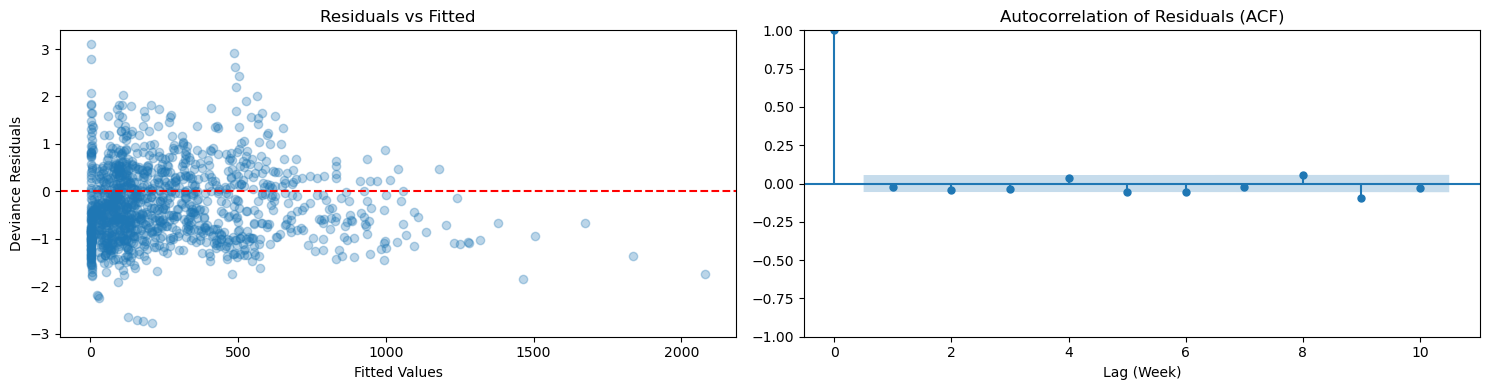

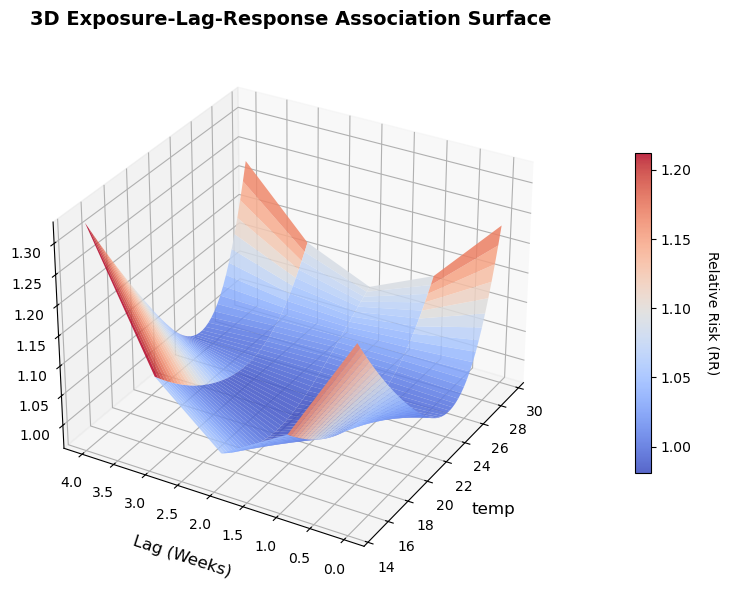

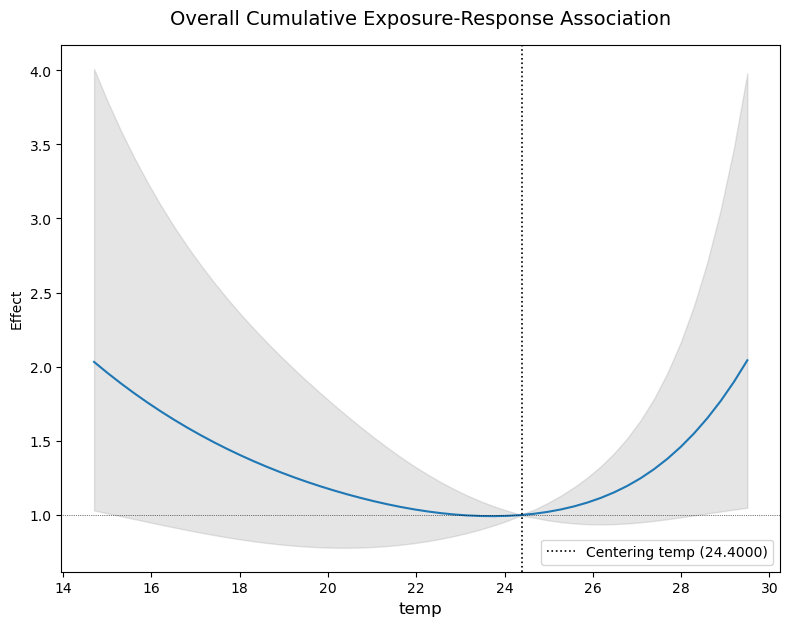

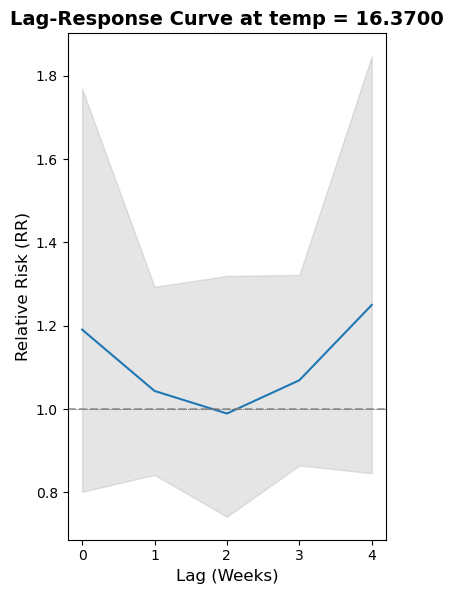

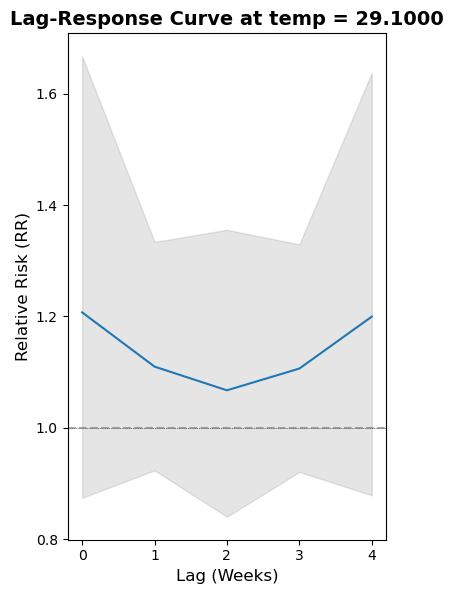

**============================== RH ==============================**

================================================== Hyperparameter tuning ==================================================
============================== Tuning CrossBasis settings ==============================
BIC for (2, 3, 2, 3): 15002.38
BIC for (2, 3, 2, 4): 14998.56
BIC for (2, 3, 3, 3): 15002.38
BIC for (2, 3, 3, 4): 14998.56
BIC for (2, 4, 2, 3): 15006.25
BIC for (2, 4, 2, 4): 15005.14
BIC for (2, 4, 3, 3): 15006.25
BIC for (2, 4, 3, 4): 15005.14
BIC for (3, 3, 2, 3): 15002.38
BIC for (3, 3, 2, 4): 14998.56
BIC for (3, 3, 3, 3): 15002.38
BIC for (3, 3, 3, 4): 14998.56
BIC for (3, 4, 2, 3): 15006.25
BIC for (3, 4, 2, 4): 15005.14
BIC for (3, 4, 3, 3): 15006.25
BIC for (3, 4, 3, 4): 15005.14
Best CrossBasis setting: (2, 3, 2, 4) (BIC = 14998.56)

============================== Tuning smoother degrees of freedom ==============================
Degrees of freedom (10, 4, 5): BIC=14787.1642 | sum(EDF)=30.8152
Degrees of freedom (10, 4, 6): BIC=14771.3674 | sum(EDF)=31.2310
Degrees 

,alpha,AIC,BIC,GCV,EDF
gcv,"[19.999999999999996, 19.999999999999996, 19.99...",14494.07457,14733.693185,1.079289,46.715678
KFold,"(630.957344480193, 15848.931924611108, 25.1188...",14534.14998,14763.664711,1.075758,44.745841



============================== Tuning Negative Binomial dispersion parameter ==============================
Dispersion   1.0: Pearson ratio = 1.1874 | BIC = 14763.6647
Dispersion   1.5: Pearson ratio = 0.8193 | BIC = 14926.6152
Dispersion   2.0: Pearson ratio = 0.6289 | BIC = 15136.9318
Dispersion   3.0: Pearson ratio = 0.4321 | BIC = 15542.2939
Dispersion   4.0: Pearson ratio = 0.3303 | BIC = 15895.7047
Dispersion   5.0: Pearson ratio = 0.2678 | BIC = 16202.5044

Best dispersion parameter: 1.5 (Pearson ratio = 0.8193)

================================================== Negative Binomial GLMGam ==================================================
                 Generalized Linear Model Regression Results                  
Dep. Variable:                  AandB   No. Observations:                 1248
Model:                         GLMGam   Df Residuals:                  1203.50
Model Family:        NegativeBinomial   Df Model:                        43.50
Link Function:                

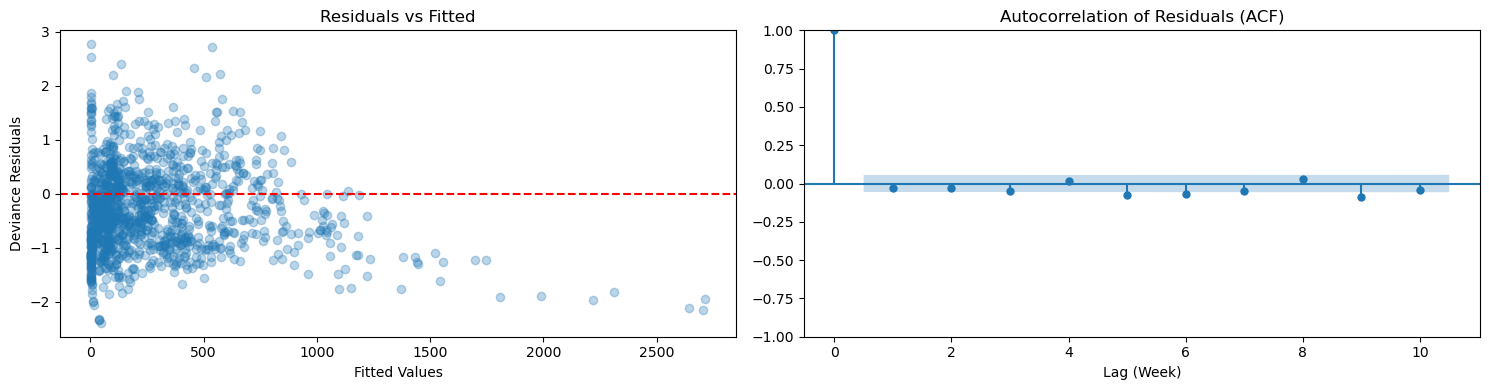

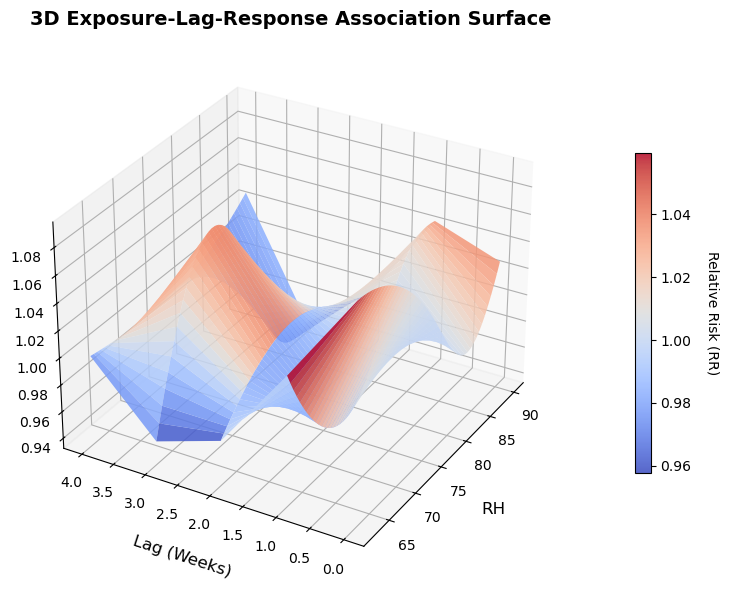

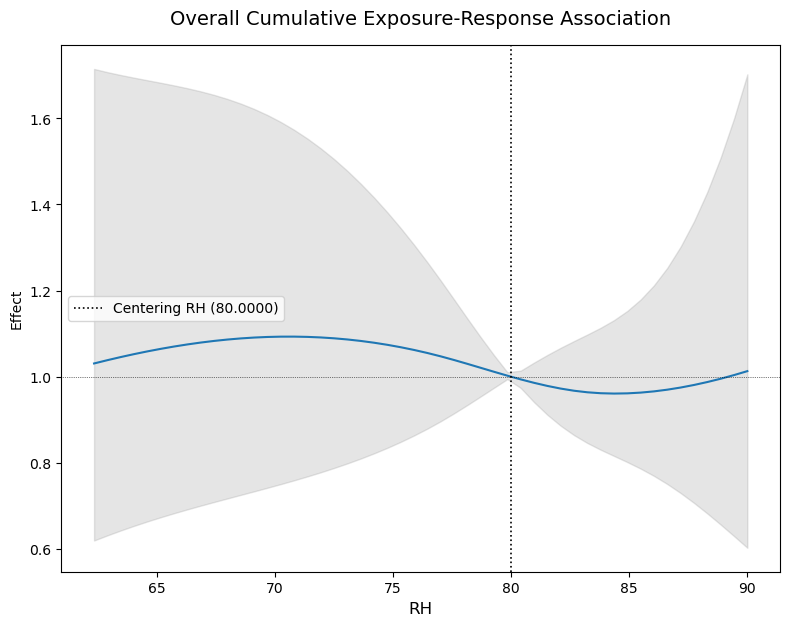

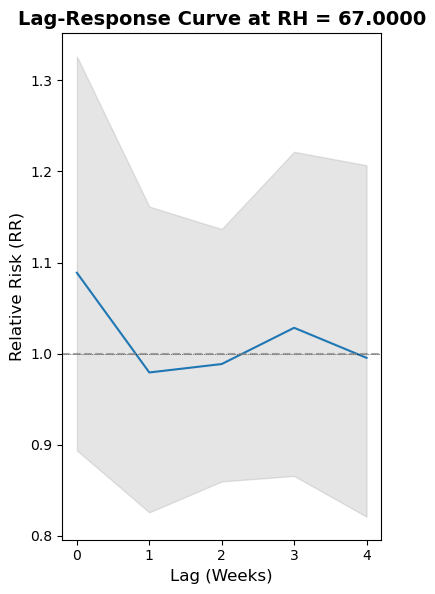

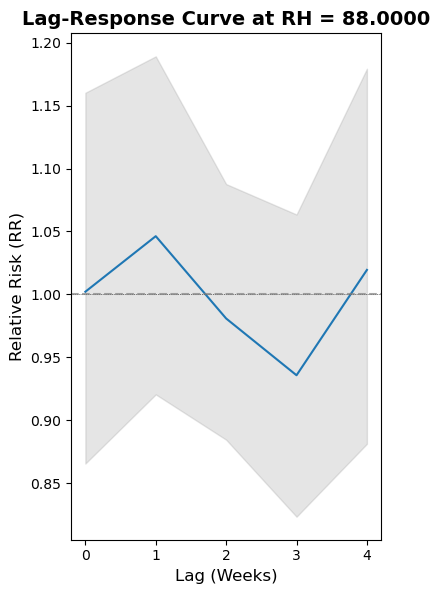

**============================== SR ==============================**

================================================== Hyperparameter tuning ==================================================
============================== Tuning CrossBasis settings ==============================
BIC for (2, 3, 2, 3): 14974.70
BIC for (2, 3, 2, 4): 14993.02
BIC for (2, 3, 3, 3): 14974.70
BIC for (2, 3, 3, 4): 14993.02
BIC for (2, 4, 2, 3): 14987.92
BIC for (2, 4, 2, 4): 15013.14
BIC for (2, 4, 3, 3): 14987.92
BIC for (2, 4, 3, 4): 15013.14
BIC for (3, 3, 2, 3): 14974.70
BIC for (3, 3, 2, 4): 14993.02
BIC for (3, 3, 3, 3): 14974.70
BIC for (3, 3, 3, 4): 14993.02
BIC for (3, 4, 2, 3): 14987.92
BIC for (3, 4, 2, 4): 15013.14
BIC for (3, 4, 3, 3): 14987.92
BIC for (3, 4, 3, 4): 15013.14
Best CrossBasis setting: (2, 3, 2, 3) (BIC = 14974.70)

============================== Tuning smoother degrees of freedom ==============================
Degrees of freedom (10, 4, 5): BIC=14755.8199 | sum(EDF)=27.9606
Degrees of freedom (10, 4, 6): BIC=14741.2602 | sum(EDF)=28.8377
Degrees 

,alpha,AIC,BIC,GCV,EDF
gcv,"[1.4057649939039733e-15, 2805.415487113929, 1....",22259.656503,22259.656503,1.0,0.0
KFold,"(5.011872336272722, 10000000.0, 1.0)",14564.203518,14781.736388,1.071593,42.409875



============================== Tuning Negative Binomial dispersion parameter ==============================
Dispersion   1.0: Pearson ratio = 1.2410 | BIC = 14781.7364
Dispersion   1.5: Pearson ratio = 0.8443 | BIC = 14934.4357
Dispersion   2.0: Pearson ratio = 0.6410 | BIC = 15139.5164
Dispersion   3.0: Pearson ratio = 0.4336 | BIC = 15540.4156
Dispersion   4.0: Pearson ratio = 0.3280 | BIC = 15892.5736
Dispersion   5.0: Pearson ratio = 0.2639 | BIC = 16199.3492

Best dispersion parameter: 1.5 (Pearson ratio = 0.8443)

================================================== Negative Binomial GLMGam ==================================================
                 Generalized Linear Model Regression Results                  
Dep. Variable:                  AandB   No. Observations:                 1248
Model:                         GLMGam   Df Residuals:                  1205.58
Model Family:        NegativeBinomial   Df Model:                        41.42
Link Function:                

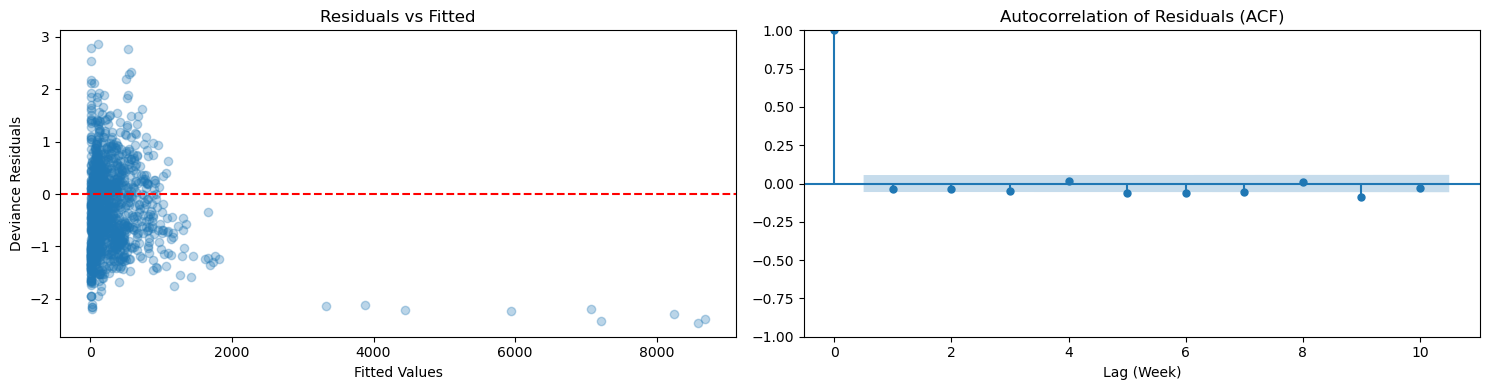

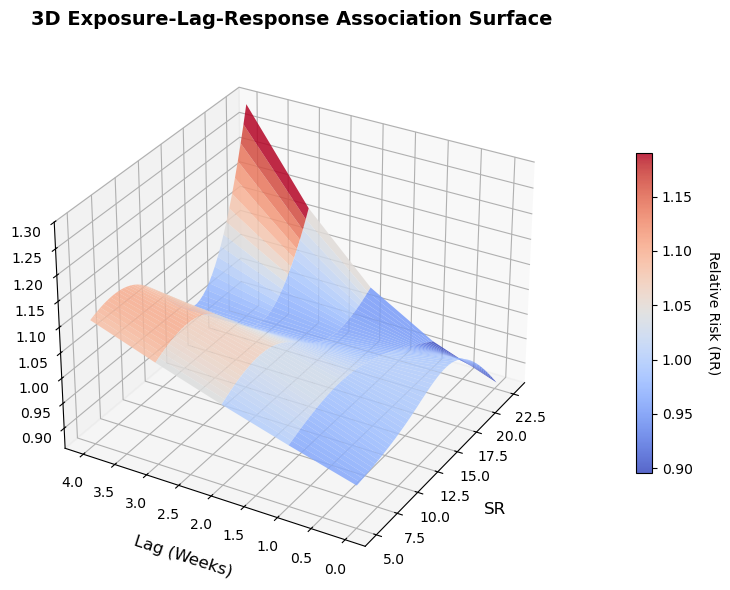

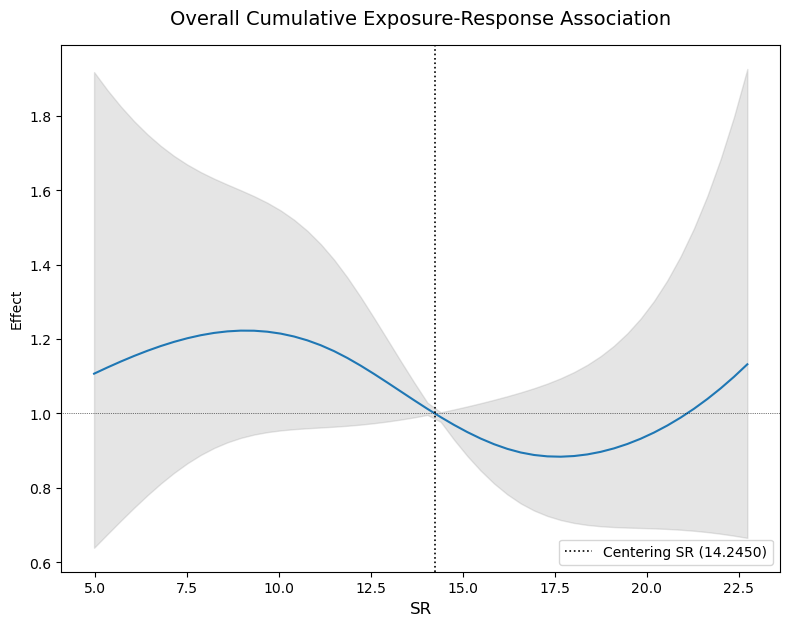

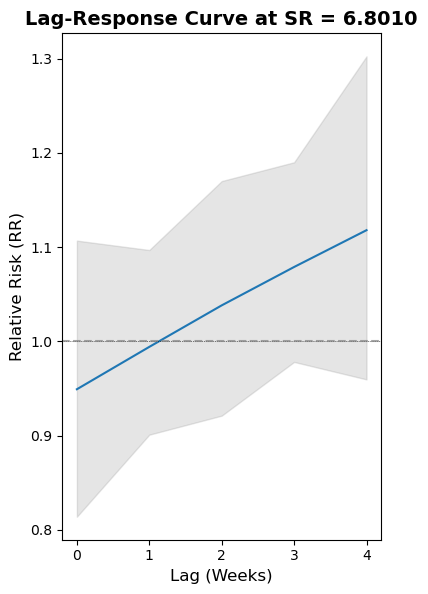

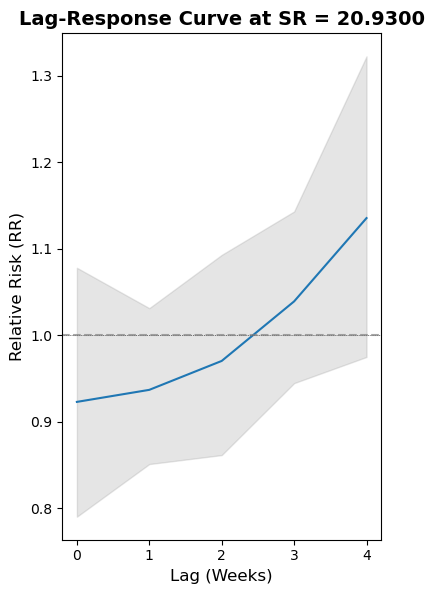

**============================== AP ==============================**

================================================== Hyperparameter tuning ==================================================
============================== Tuning CrossBasis settings ==============================
BIC for (2, 3, 2, 3): 14981.39
BIC for (2, 3, 2, 4): 14997.62
BIC for (2, 3, 3, 3): 14981.39
BIC for (2, 3, 3, 4): 14997.62
BIC for (2, 4, 2, 3): 14992.38
BIC for (2, 4, 2, 4): 15015.83
BIC for (2, 4, 3, 3): 14992.38
BIC for (2, 4, 3, 4): 15015.83
BIC for (3, 3, 2, 3): 14981.39
BIC for (3, 3, 2, 4): 14997.62
BIC for (3, 3, 3, 3): 14981.39
BIC for (3, 3, 3, 4): 14997.62
BIC for (3, 4, 2, 3): 14992.38
BIC for (3, 4, 2, 4): 15015.83
BIC for (3, 4, 3, 3): 14992.38
BIC for (3, 4, 3, 4): 15015.83
Best CrossBasis setting: (2, 3, 2, 3) (BIC = 14981.39)

============================== Tuning smoother degrees of freedom ==============================
Degrees of freedom (10, 4, 5): BIC=14757.4511 | sum(EDF)=27.8230
Degrees of freedom (10, 4, 6): BIC=14749.2866 | sum(EDF)=28.7668
Degrees 

,alpha,AIC,BIC,GCV,EDF
gcv,"[8.324501793396742, 27.429034302309226, 108.53...",14453.684968,14601.088508,1.047695,28.737569
KFold,"(125.89254117941663, 1995262.3149688789, 25.11...",14576.318154,14792.198342,1.07102,42.087671



============================== Tuning Negative Binomial dispersion parameter ==============================
Dispersion   1.0: Pearson ratio = 1.2848 | BIC = 14792.1983
Dispersion   1.5: Pearson ratio = 0.8721 | BIC = 14928.1039
Dispersion   2.0: Pearson ratio = 0.6627 | BIC = 15139.5374
Dispersion   3.0: Pearson ratio = 0.4483 | BIC = 15536.9756
Dispersion   4.0: Pearson ratio = 0.3391 | BIC = 15884.9299
Dispersion   5.0: Pearson ratio = 0.2730 | BIC = 16190.2021

Best dispersion parameter: 1.5 (Pearson ratio = 0.8721)

================================================== Negative Binomial GLMGam ==================================================
                 Generalized Linear Model Regression Results                  
Dep. Variable:                  AandB   No. Observations:                 1248
Model:                         GLMGam   Df Residuals:                  1207.70
Model Family:        NegativeBinomial   Df Model:                        39.30
Link Function:                

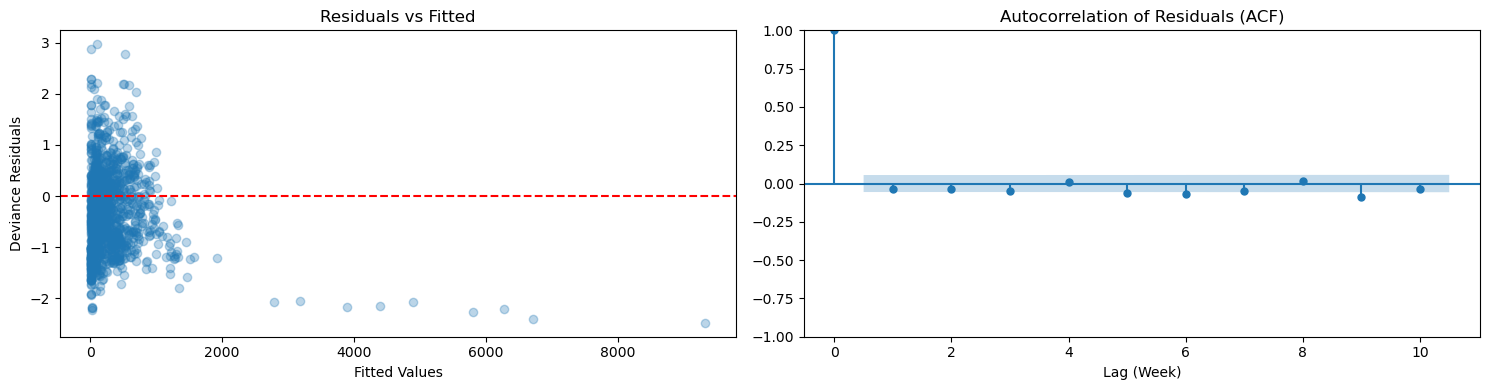

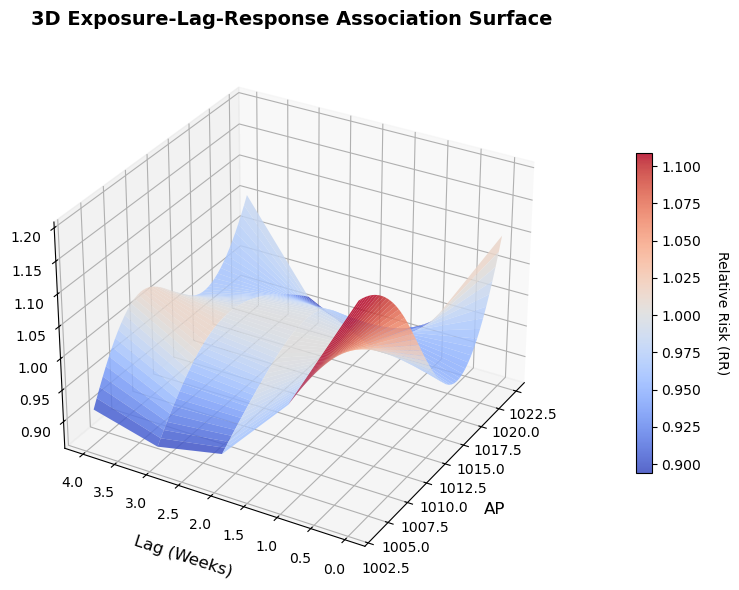

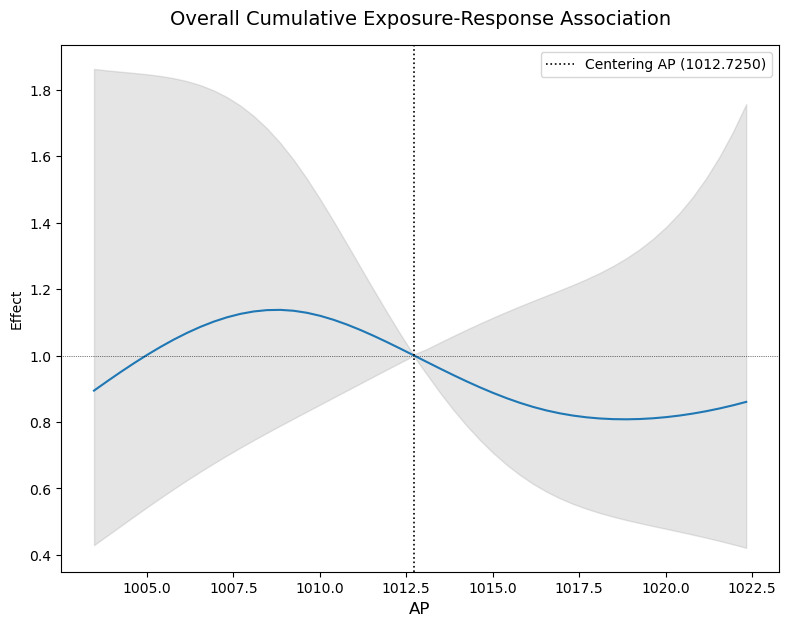

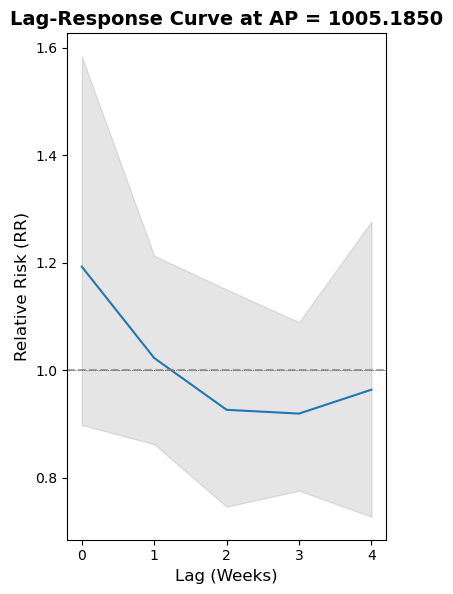

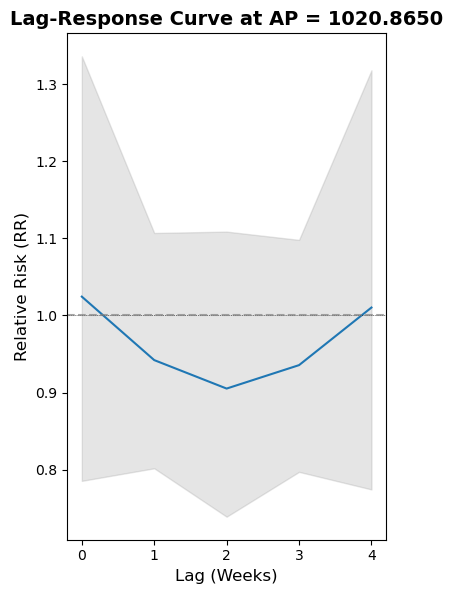

**============================== DPT ==============================**

================================================== Hyperparameter tuning ==================================================
============================== Tuning CrossBasis settings ==============================
BIC for (2, 3, 2, 3): 14932.44
BIC for (2, 3, 2, 4): 14932.95
BIC for (2, 3, 3, 3): 14932.44
BIC for (2, 3, 3, 4): 14932.95
BIC for (2, 4, 2, 3): 14941.62
BIC for (2, 4, 2, 4): 14950.25
BIC for (2, 4, 3, 3): 14941.62
BIC for (2, 4, 3, 4): 14950.25
BIC for (3, 3, 2, 3): 14932.44
BIC for (3, 3, 2, 4): 14932.95
BIC for (3, 3, 3, 3): 14932.44
BIC for (3, 3, 3, 4): 14932.95
BIC for (3, 4, 2, 3): 14941.62
BIC for (3, 4, 2, 4): 14950.25
BIC for (3, 4, 3, 3): 14941.62
BIC for (3, 4, 3, 4): 14950.25
Best CrossBasis setting: (2, 3, 2, 3) (BIC = 14932.44)

============================== Tuning smoother degrees of freedom ==============================
Degrees of freedom (10, 4, 5): BIC=14753.2349 | sum(EDF)=27.6630
Degrees of freedom (10, 4, 6): BIC=14746.3799 | sum(EDF)=28.4070
Degrees 

,alpha,AIC,BIC,GCV,EDF
gcv,"[5.736532143866815, 7.0705209877500295, 175.42...",14520.032066,14825.851179,1.102859,59.622026
KFold,"(1.0, 630.957344480193, 25.118864315095795)",14489.613389,14707.723112,1.071793,42.522338



============================== Tuning Negative Binomial dispersion parameter ==============================
Dispersion   1.0: Pearson ratio = 1.1682 | BIC = 14707.7231
Dispersion   1.5: Pearson ratio = 0.8026 | BIC = 14879.4247
Dispersion   2.0: Pearson ratio = 0.6125 | BIC = 15095.0076
Dispersion   3.0: Pearson ratio = 0.4159 | BIC = 15507.9455
Dispersion   4.0: Pearson ratio = 0.3157 | BIC = 15868.7948
Dispersion   5.0: Pearson ratio = 0.2547 | BIC = 16178.8548

Best dispersion parameter: 1.0 (Pearson ratio = 1.1682)

================================================== Negative Binomial GLMGam ==================================================
                 Generalized Linear Model Regression Results                  
Dep. Variable:                  AandB   No. Observations:                 1248
Model:                         GLMGam   Df Residuals:                  1205.48
Model Family:        NegativeBinomial   Df Model:                        41.52
Link Function:                

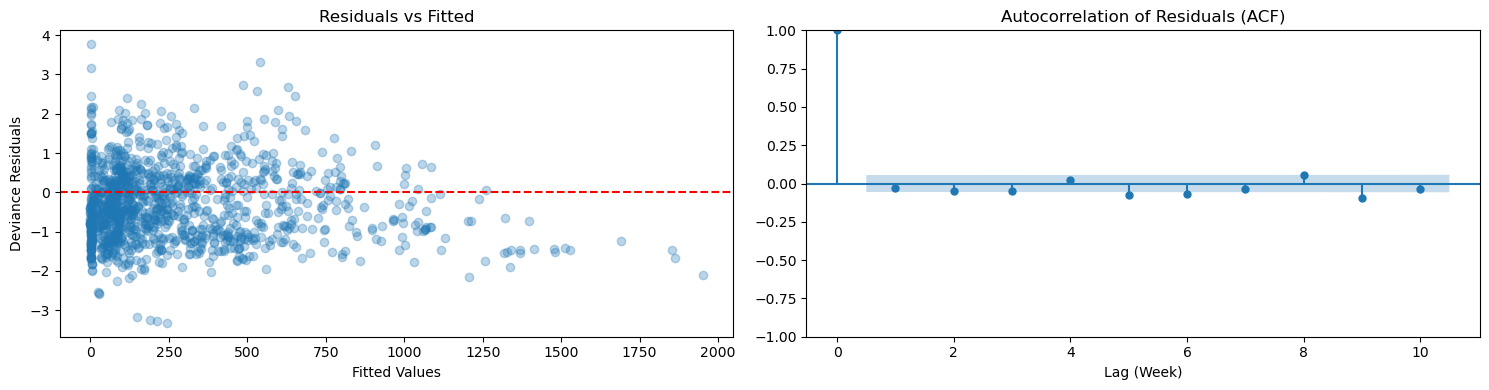

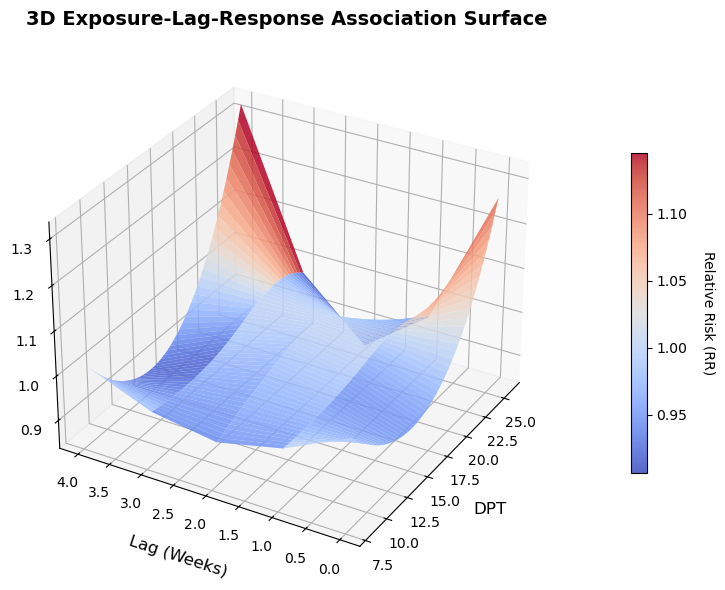

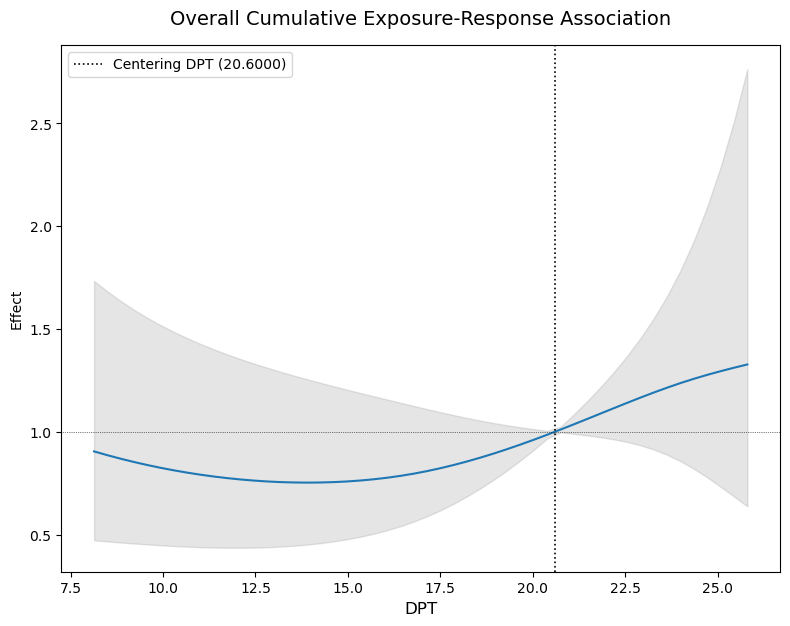

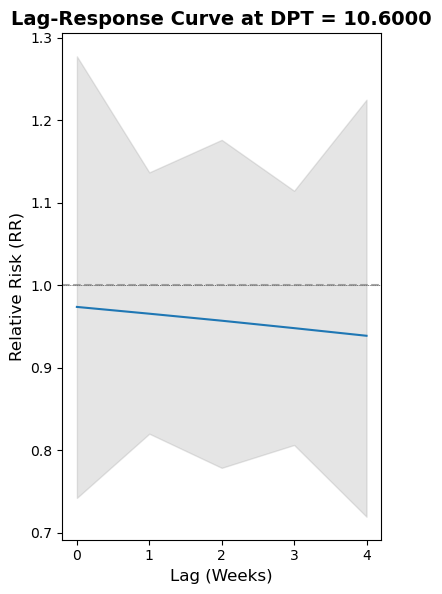

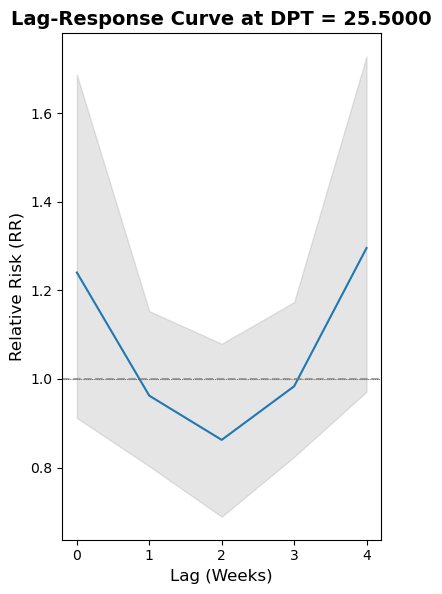

**============================== WS ==============================**

================================================== Hyperparameter tuning ==================================================
============================== Tuning CrossBasis settings ==============================
BIC for (2, 3, 2, 3): 15000.57
BIC for (2, 3, 2, 4): 15003.35
BIC for (2, 3, 3, 3): 15000.57
BIC for (2, 3, 3, 4): 15003.35
BIC for (2, 4, 2, 3): 15009.70
BIC for (2, 4, 2, 4): 15018.86
BIC for (2, 4, 3, 3): 15009.70
BIC for (2, 4, 3, 4): 15018.86
BIC for (3, 3, 2, 3): 15000.57
BIC for (3, 3, 2, 4): 15003.35
BIC for (3, 3, 3, 3): 15000.57
BIC for (3, 3, 3, 4): 15003.35
BIC for (3, 4, 2, 3): 15009.70
BIC for (3, 4, 2, 4): 15018.86
BIC for (3, 4, 3, 3): 15009.70
BIC for (3, 4, 3, 4): 15018.86
Best CrossBasis setting: (2, 3, 2, 3) (BIC = 15000.57)

============================== Tuning smoother degrees of freedom ==============================
Degrees of freedom (10, 4, 5): BIC=14767.0897 | sum(EDF)=28.0039
Degrees of freedom (10, 4, 6): BIC=14755.0528 | sum(EDF)=28.9331
Degrees 

,alpha,AIC,BIC,GCV,EDF
gcv,"[7.030852798282695, 35.00282441966199, 137.785...",14500.843129,14767.730874,1.088905,52.032026
KFold,"(3162.2776601683795, 1.0, 125.89254117941663)",14574.359875,15025.897668,1.157541,88.031117



============================== Tuning Negative Binomial dispersion parameter ==============================
Dispersion   1.0: Pearson ratio = 1.2511 | BIC = 15025.8977
Dispersion   1.5: Pearson ratio = 0.8344 | BIC = 14884.9403
Dispersion   2.0: Pearson ratio = 0.6421 | BIC = 15106.2190
Dispersion   3.0: Pearson ratio = 0.4405 | BIC = 15475.4850
Dispersion   4.0: Pearson ratio = 0.3382 | BIC = 15839.3092
Dispersion   5.0: Pearson ratio = 0.2802 | BIC = 16262.0298

Best dispersion parameter: 1.5 (Pearson ratio = 0.8344)

================================================== Negative Binomial GLMGam ==================================================
                 Generalized Linear Model Regression Results                  
Dep. Variable:                  AandB   No. Observations:                 1248
Model:                         GLMGam   Df Residuals:                  1204.20
Model Family:        NegativeBinomial   Df Model:                        42.80
Link Function:                

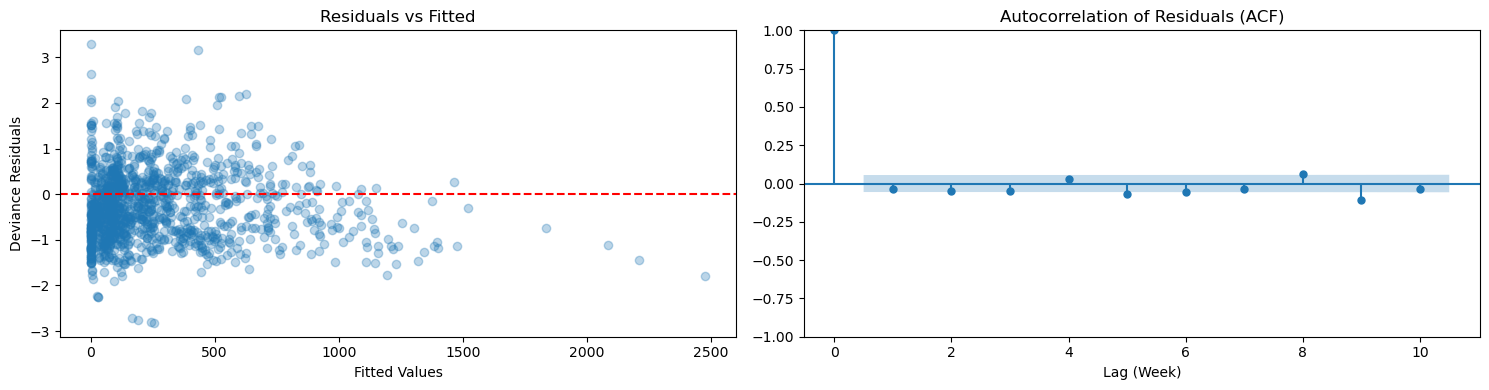

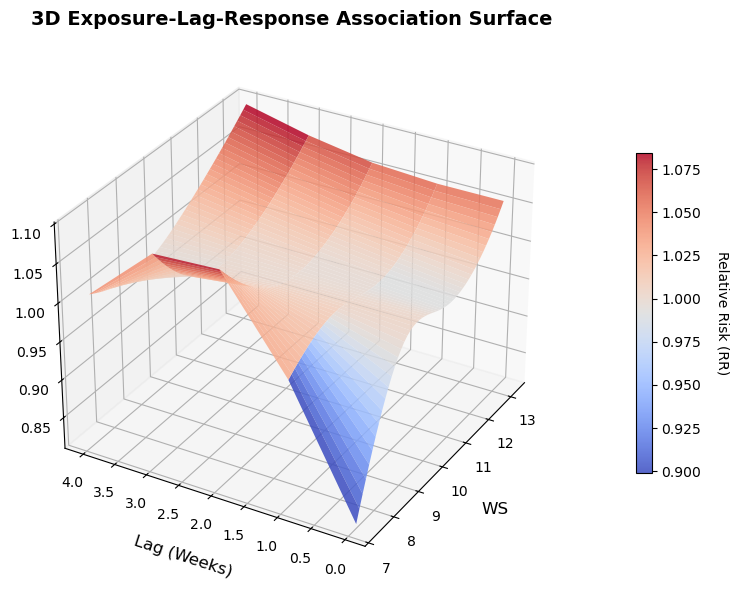

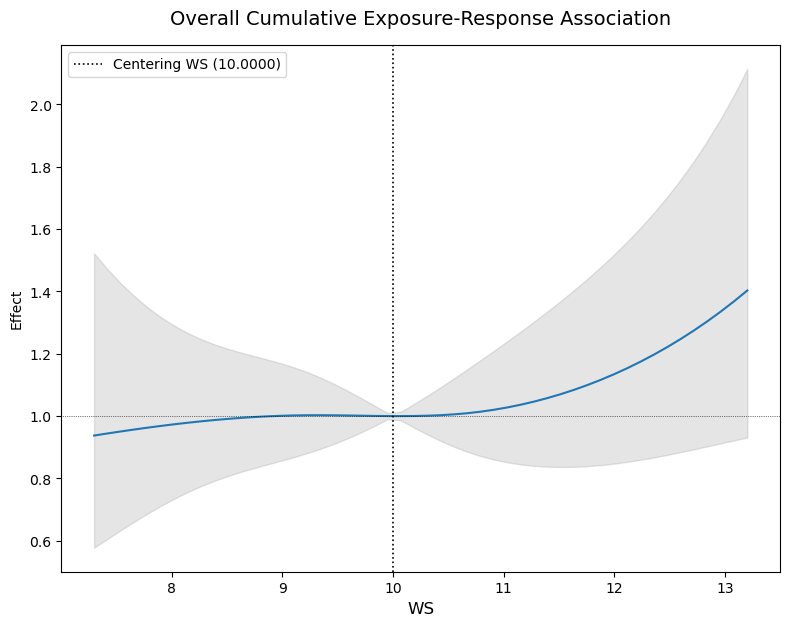

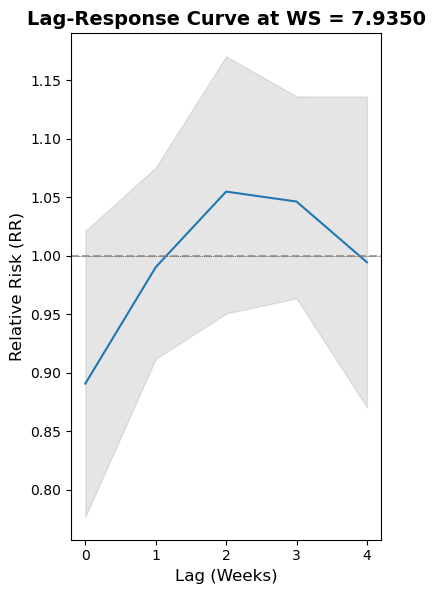

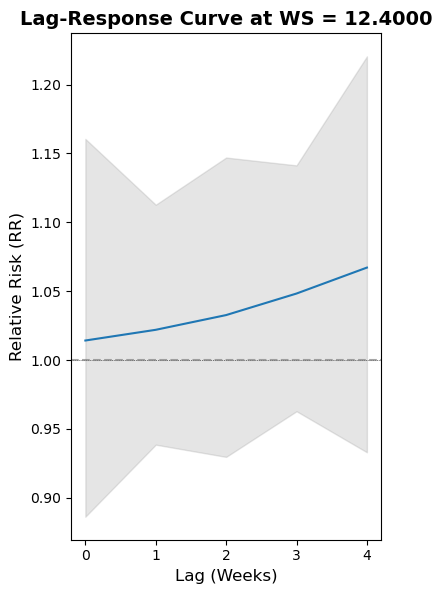

**============================== UV ==============================**

================================================== Hyperparameter tuning ==================================================
============================== Tuning CrossBasis settings ==============================
BIC for (2, 3, 2, 3): 14992.08
BIC for (2, 3, 2, 4): 15011.46
BIC for (2, 3, 3, 3): 14992.08
BIC for (2, 3, 3, 4): 15011.46
BIC for (2, 4, 2, 3): 15005.44
BIC for (2, 4, 2, 4): 15027.31
BIC for (2, 4, 3, 3): 15005.44
BIC for (2, 4, 3, 4): 15027.31
BIC for (3, 3, 2, 3): 14992.08
BIC for (3, 3, 2, 4): 15011.46
BIC for (3, 3, 3, 3): 14992.08
BIC for (3, 3, 3, 4): 15011.46
BIC for (3, 4, 2, 3): 15005.44
BIC for (3, 4, 2, 4): 15027.31
BIC for (3, 4, 3, 3): 15005.44
BIC for (3, 4, 3, 4): 15027.31
Best CrossBasis setting: (2, 3, 2, 3) (BIC = 14992.08)

============================== Tuning smoother degrees of freedom ==============================
Degrees of freedom (10, 4, 5): BIC=14768.2267 | sum(EDF)=28.0008
Degrees of freedom (10, 4, 6): BIC=14753.7588 | sum(EDF)=28.8615
Degrees 

,alpha,AIC,BIC,GCV,EDF
gcv,"[6.523775191139986, 36.156526826234085, 82.924...",14523.841727,14868.59596,1.117084,67.212758
KFold,"(1.0, 25.118864315095795, 125.89254117941663)",14502.700654,14791.862035,1.096856,56.37446



============================== Tuning Negative Binomial dispersion parameter ==============================
Dispersion   1.0: Pearson ratio = 1.1575 | BIC = 14791.8620
Dispersion   1.5: Pearson ratio = 0.7812 | BIC = 14817.6488
Dispersion   2.0: Pearson ratio = 0.5982 | BIC = 15053.6466
Dispersion   3.0: Pearson ratio = 0.4137 | BIC = 15584.9206
Dispersion   4.0: Pearson ratio = 0.3130 | BIC = 15866.5300
Dispersion   5.0: Pearson ratio = 0.2543 | BIC = 16198.6052

Best dispersion parameter: 1.0 (Pearson ratio = 1.1575)

================================================== Negative Binomial GLMGam ==================================================
                 Generalized Linear Model Regression Results                  
Dep. Variable:                  AandB   No. Observations:                 1248
Model:                         GLMGam   Df Residuals:                  1191.63
Model Family:        NegativeBinomial   Df Model:                        55.37
Link Function:                

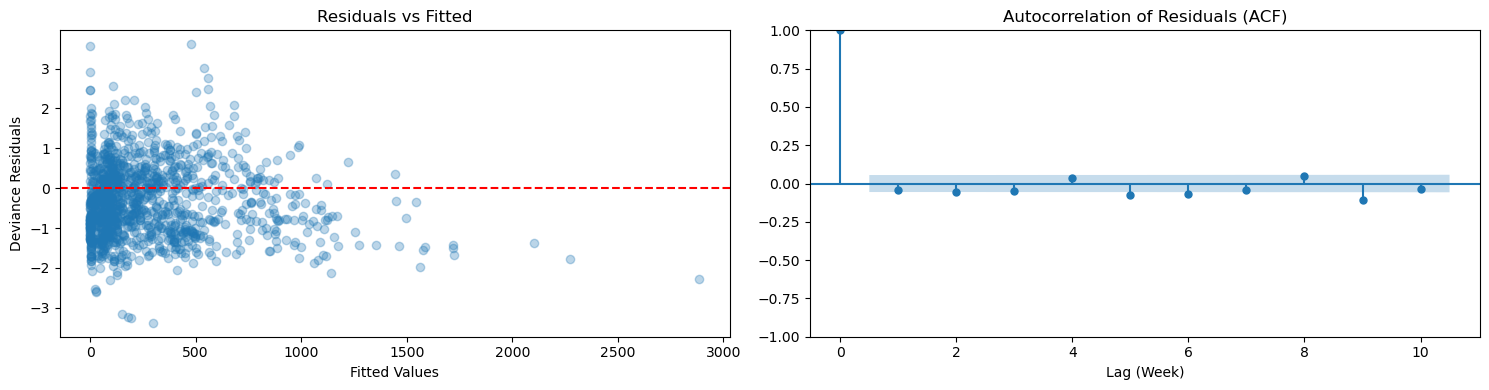

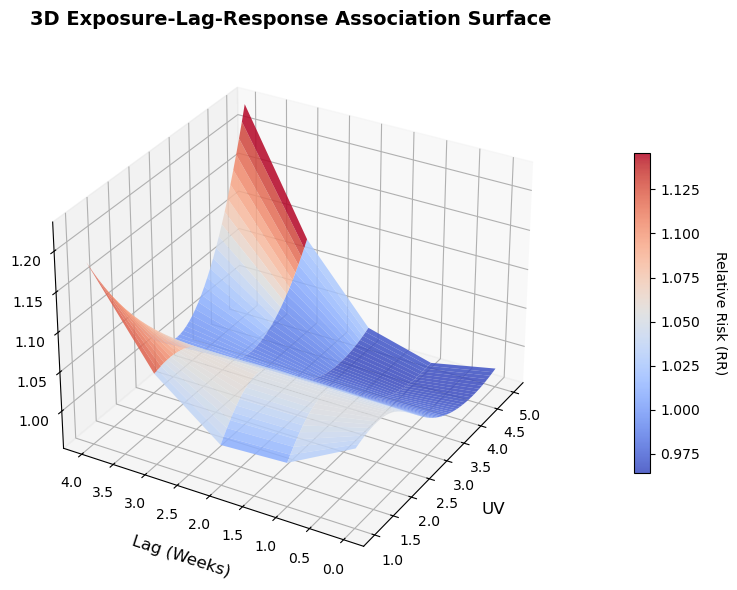

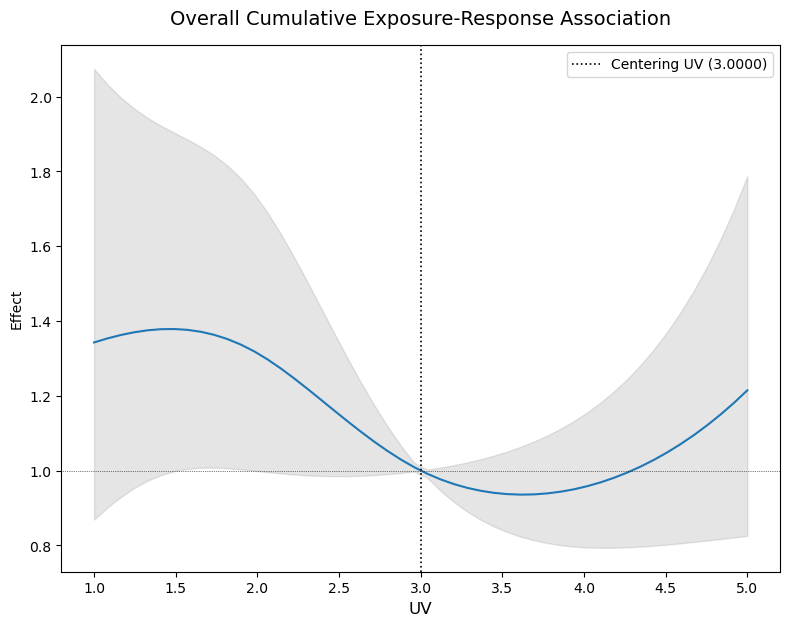

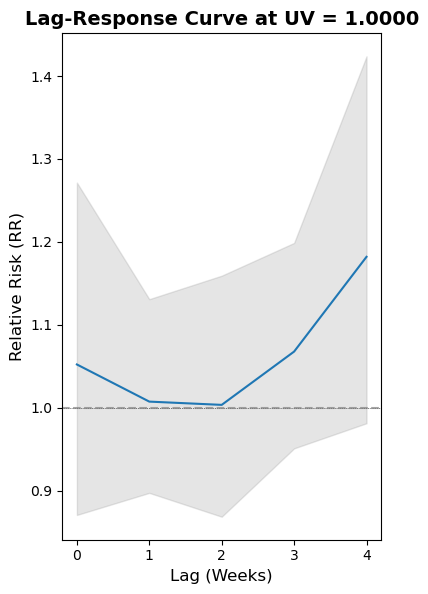

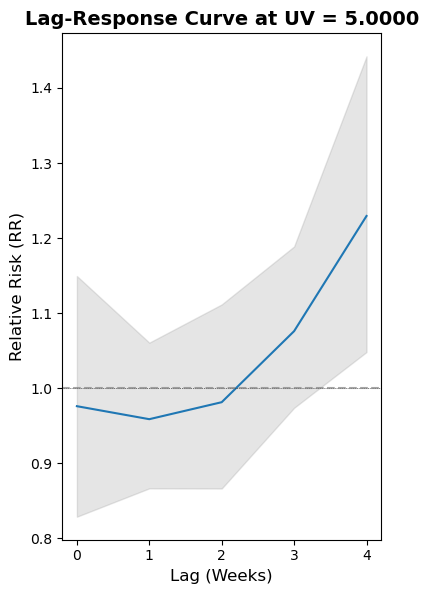

In [23]:
# All meteorological variables for AandB
tar_var = "AandB"
for exp in mete_col:
    exp_col_list = [exp]

    display(Markdown(f"**{'='*30} {exp} {'='*30}**"))

    pred, model_data, cb_list, nb_result = DLNM_NB(
        df, max_lag=4, 
        tar_var=tar_var, exp_col_list=exp_col_list, linear_predictors_list=linear_predictors_list,
        bs_name_lst=bs_name_lst, ccs_name_lst=ccs_name_lst,
        cb_grid=cb_grid, smoother_grid=smoother_grid, disp_grid=disp_grid, criterion_lst=["gcv"]
    )
